# Show a solution, ban it, see what replaces it

**Exposure-ban experiment (Step 1b) on Qwen3-8B** (bf16, thinking off, vLLM 0.11.0, revision `b968826d`) over the 12 frozen tasks of the exp11 algorithm-choice bench.

**The question.** A coding model is shown a correct program that uses algorithm **Y**, and is then told not to use Y. What does it write instead?

Four forecasts of the replacement were fixed and sha256 hash-chained *before* any ban sample was drawn:

| family | forecast of the replacement |
|---|---|
| **LADDER** | the model's context-free default algorithm for the task |
| **ASSOCIATE** | the model's own modal answer to "what is the standard alternative to Y?" (asked and frozen earlier) |
| **PROXIMITY** | the surviving algorithm whose reference programs are nearest the shown program (Zhang-Shasha tree-edit distance on identifier-normalised ASTs) |
| **SUBTRACT-IN-CONTEXT** | where the model lands when Y's distinctive token n-gram is vetoed during decoding, under the same prompt with *no* ban text (iterated, persistent signature veto) |

**The prompts.** There are 33 eligible non-default algorithms Y. Nineteen of them are *priority* Y, whose associate differs from the default. For each Y, the prompt shows up to 5 name-scrubbed correct programs of Y, then asks one of three things:
- **COPY** (the matched twin): `Write a correct solution.`
- **NAMED**: `Write a correct solution that does not use {Y}.`
- **UNNAMED**: `Write a correct solution that uses a different algorithm from the one above.`

There are N = 50 samples per Y and arm. The seed of each (task, Y, shown program, sample index) is shared by every arm, so the arms use common random numbers.

**What this notebook runs.** `method.py` is a CLI with 8 subcommands. Four of them cannot run in a 10-minute CPU demo:
- `setup` and `forecasts` need the exp11 bench.
- `stage1` and `stage2` need one GPU running Qwen3-8B on vLLM for about 35 GPU-minutes. They generate and label 10,600 programs.

Their outputs are condensed into `mini_demo_data.json`: all **66 events** (33 Y × NAMED / UNNAMED). Each event carries its landing counts, its gate statistics and the four committed forecasts. The notebook re-runs every CPU step on them, with the original code:

| `method.py` subcommand | in this notebook |
|---|---|
| `setup`, `forecasts` (bench) | shown as code; their outputs (defaults, associates, PROXIMITY forecasts, allocation, prompts) are rebuilt from the data |
| `commit1` | **runs**: the forecasts and the frozen analysis code are sha256 hash-chained (COMMIT #1) |
| `stage1` (GPU) | **runs on CPU**: the original n-gram-veto logits processor drives a toy decoder through the smoke tests, and SUBTRACT-IN-CONTEXT is recomputed from the stored veto rounds |
| `commit2` | **runs**: COMMIT #2 and chain verification |
| `stage2` (GPU) | the NAMED / UNNAMED outcomes are read from the data |
| `analyze` | **runs**: the frozen C1 analysis (scoring, advance rule, Holm-corrected paired Wilcoxon tests, task-cluster bootstrap CIs, branch, sensitivities, placebos) |
| `audit` | **runs**: the independent re-derivation `audit/rederive.py`, with its placebos |

## Setup: dependencies, imports and data

The install cell follows the Colab pattern. On Colab the pre-installed scientific stack is used as is. Locally the same versions are installed, plus `loguru`, which `method.py` uses for logging. `torch` is only needed for the n-gram-veto logits processor of section 4.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (method.py logs through loguru; version pinned in the artifact's requirements.txt)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, pandas, torch — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pandas==2.2.2')
    _pip('torch==2.9.0+cpu', '--extra-index-url', 'https://download.pytorch.org/whl/cpu')

In [2]:
from __future__ import annotations

# --- method.py import block (as in the original) ---
import argparse
import json
import math
import os
import resource
import subprocess
import sys
import tarfile
import time
from pathlib import Path

from loguru import logger

# --- imports of the modules method.py drives (exposure/core.py, exposure/report.py, exposure/veto.py, exposure/ngram.py) ---
import hashlib
import random
import re
import statistics
import threading
from collections import Counter, defaultdict

import numpy as np
import torch

# --- notebook-only additions: a scratch folder, inline figures and tables ---
import shutil

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-3/experiment-14/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
events_raw = data["datasets"][0]["examples"]
print(data["metadata"]["title"])
print(f"dataset '{data['datasets'][0]['dataset']}': {len(events_raw)} events "
      f"{dict(Counter(e['metadata_event_type'] for e in events_raw))}")
print("one event (T03 = k-th smallest, Y = size-k heap, NAMED):")
print({k: events_raw[0][k] for k in ("output", "predict_ladder", "predict_associate", "predict_proximity",
                                     "metadata_avoidance", "metadata_n_nonY", "metadata_landing_counts")})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Show a solution, ban it, see what replaces it (exposure-ban experiment, Qwen3-8B bf16) - demo subset
dataset 'exposure_events': 66 events {'exposure_named': 33, 'exposure_unnamed': 33}
one event (T03 = k-th smallest, Y = size-k heap, NAMED):
{'output': 'full_sort', 'predict_ladder': 'full_sort', 'predict_associate': 'quickselect', 'predict_proximity': 'heapify_pop', 'metadata_avoidance': 0.19999999999999996, 'metadata_n_nonY': 10, 'metadata_landing_counts': {'full_sort': 10}}


## Configuration

Every tunable quantity of the CPU analysis is set here. The comments give the values of the original full run.

- **Scope:** `N_Y` picks how many banned algorithms Y, in the frozen task order, enter the analysis. Each Y gives one NAMED and one UNNAMED event.
- **Resampling sizes:** the bootstrap and placebo sizes control how many resamples or draws the tests use.
- **Fixed inside the frozen module:** the rotation placebo inside `analysis/c1.py` always uses 2,000 resamples.

With the original values, the numbers printed below reproduce the published `results/c1_summary.json`.

In [5]:
# ---- tunable parameters (value of the original full run in the comment) ----
N_Y = 33                  # banned algorithms Y analysed, in the frozen order (one NAMED + one UNNAMED event each); original: 33 (all)
N_BOOT = 10_000           # task-cluster bootstrap resamples of the primary paired tests (analysis/c1.py N_BOOT); original: 10_000
N_BOOT_SECONDARY = 2_000  # bootstrap resamples in the sensitivities and the exploratory three-family CIs; original: 2_000
N_PERM_DRAWS = 200        # label-permutation placebo draws (exposure/report.py); original: 200
N_SIGNFLIP_DRAWS = 200    # sign-flip placebo draws (audit/rederive.py); original: 200
N_TWINS = 20              # COPY / veto twin pairs in the toy smoke tests (exposure/sampling.py: 20 Qwen3-8B twins); original: 20

## 1. Constants, prompt wordings and helpers (`exposure/core.py`)

`method.py` imports its paths, constants and helpers from `exposure/core.py`.

**Paths.** The original derives every path from the workspace root. Here they point to a scratch folder, `demo_run/`, which is emptied at the start of each run. It receives what the original writes to `predictions/`, `results/`, `figures/`, `logs/` and `commitments.log`.

**What the constants fix:**
- the three prompt wordings (W5 = NAMED) and the W1–W4 template arm;
- the veto parameters: n-grams up to 6 tokens; presence ≥ 0.8; at most 3 rounds; re-emergence threshold 0.20; ≥ 20 non-Y attempts for SUBTRACT to be defined;
- the common-random-number seed rule `seed_of`.

Four helpers are left out: `task_dir`, `load_spec`, `load_tokenizer` and `ensure_bench_importable`. They read the exp11 bench or the Qwen3-8B tokenizer, and nothing in this demo calls them.

In [6]:
# ---------------------------------------------------------------- exposure/core.py (paths: notebook scratch folder)
ROOT = Path("demo_run")                 # original: Path(__file__).resolve().parent.parent (the workspace root)
shutil.rmtree(ROOT, ignore_errors=True)  # notebook-only: every run starts from an empty folder
DATA = ROOT / "data"
PRED = ROOT / "predictions"
RESULTS = ROOT / "results"
FIGS = ROOT / "figures"
LOGS = ROOT / "logs"
COMMIT_LOG = ROOT / "commitments.log"
for _d in (DATA, PRED, RESULTS, FIGS, LOGS, ROOT / "analysis", ROOT / "audit", ROOT / "tests"):
    _d.mkdir(parents=True, exist_ok=True)
(ROOT / "analysis" / "__init__.py").write_text("")
sys.path.insert(0, str(ROOT))           # as method.py: the workspace root is importable (`from analysis import c1`)

MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REV = "b968826d9c46dd6066d109eabc6255188de91218"  # the main revision on 2026-10-20; exp8 used b968826d
DTYPE = "bfloat16"
BASE_SEED = 20261020
SHUFFLE_SEED = 20261020  # committed seed of the shown-program shuffle and the proximity reference selection

# Stage-A order of the 12 frozen tasks (exp11 commitments.log, stageA_order minus the excluded R2)
TASK_ORDER = ["T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11"]

N_PER_ARM = 50
MAX_SHOWN = 5
MAX_SHOWN_TOKENS = 600
NGRAM_MAX = 6
PRESENCE_MIN = 0.8
COVETO_SHARE = 0.5
REEMERGE_MIN = 0.20
MAX_ROUNDS = 3
MIN_NONY_SUBTRACT = 20
N_BASELINE_CHECK = 20
MAX_MODEL_LEN = 2048
MAX_NEW_TOKENS = 1024
JUDGE_SOFT_CAP = 0.50  # stop new judge calls (USD); the hard cap of the plan is 0.60

NL = "\n"
INTRO = "Here is a correct solution to this task:"
WORDINGS = {
    "copy": "Write a correct solution.",
    "named": "Write a correct solution that does not use {x}.",  # = frozen template W5
    "unnamed": "Write a correct solution that uses a different algorithm from the one above.",
}
# Frozen ban templates W1-W4 of the shared protocol (round-2 prompts_v2.json); W5 is the NAMED wording above.
TEMPLATES_W1_W4 = {
    "W1": "Do not use {x} for this task.",
    "W2": "Your solution must not rely on {x}.",
    "W3": "Avoid {x} entirely.",
    "W4": "{x} is not allowed here.",
}


def setup_logging(name: str) -> None:
    LOGS.mkdir(parents=True, exist_ok=True)
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(LOGS / f"{name}.log", rotation="30 MB", level="DEBUG")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with Path(p).open("rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def canon_json(obj) -> str:
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False)


def seed_of(key: str) -> int:
    """Seed shared by every arm of one (task, Y, shown program, sample index): common random numbers."""
    return int(sha256_text(key)[:8], 16)


def read_jsonl(p: Path) -> list[dict]:
    if not Path(p).exists():
        return []
    out = []
    with Path(p).open() as f:
        for line in f:
            line = line.strip()
            if line:
                out.append(json.loads(line))
    return out


_write_lock = threading.Lock()


def append_jsonl(p: Path, rows: list[dict]) -> None:
    with _write_lock, Path(p).open("a") as f:
        for r in rows:
            f.write(json.dumps(r) + "\n")
        f.flush()


def write_json(p: Path, obj, indent: int = 1) -> None:
    Path(p).parent.mkdir(parents=True, exist_ok=True)
    Path(p).write_text(json.dumps(obj, indent=indent, default=_json_default))


def _json_default(o):
    if hasattr(o, "item"):
        return o.item()
    if isinstance(o, (set, tuple)):
        return list(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def read_json(p: Path):
    return json.loads(Path(p).read_text())


def fenced(code: str) -> str:
    """The exact fenced text used for n-gram tokenisation and for the shown-program prompt block."""
    return "```python" + NL + code.rstrip() + NL + "```"


def wilson(k: int, n: int, z: float = 1.959964) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0.0, c - h), min(1.0, c + h))


class Timer:
    """Accumulates wall and GPU seconds per stage into results/timings.json."""

    path = RESULTS / "timings.json"

    def __init__(self, stage: str, gpu: bool = False):
        self.stage, self.gpu = stage, gpu

    def __enter__(self):
        self.t0 = time.time()
        return self

    def __exit__(self, *exc):
        dt = time.time() - self.t0
        RESULTS.mkdir(exist_ok=True)
        tm = read_json(self.path) if self.path.exists() else {}
        e = tm.setdefault(self.stage, {"wall_s": 0.0, "gpu_s": 0.0, "runs": 0})
        e["wall_s"] += dt
        e["gpu_s"] += dt if self.gpu else 0.0
        e["runs"] += 1
        e["last_end_utc"] = time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())
        write_json(self.path, tm)
        logger.info(f"[timing] {self.stage}: {dt:.1f}s ({'GPU' if self.gpu else 'CPU'})")
        return False


def deviation(text: str) -> None:
    """Record a declared deviation from the plan (results/deviations.jsonl), deduplicated by text."""
    p = RESULTS / "deviations.jsonl"
    RESULTS.mkdir(exist_ok=True)
    have = {r["text"] for r in read_jsonl(p)}
    if text not in have:
        append_jsonl(p, [{"ts": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()), "text": text}])
        logger.warning(f"DEVIATION: {text}")

### `method.py`: CPU count, environment record, command line

These are the helpers at the top of `method.py`:
- **`_detect_cpus`** reads the cgroup CPU quota rather than the host core count.
- **`env_info`** records the environment that `setup` writes to `results/environment.json`.
- **`main()`** parses the command line.

A notebook has no command line, so the parser gets an explicit argument list. `run_banner` does what `main()` does before it dispatches a subcommand: it opens the per-command log and prints the banner. `_cpu_ram_limit`, the address-space cap of the CPU subcommands, is defined but not applied here, because it would cap the whole Jupyter kernel.

In [7]:
METHOD_DOC = """Show a solution, ban it, see what replaces it: Step-1b exposure-ban experiment on Qwen3-8B (bf16, thinking off).

Subcommands (run in this order):
  setup      copy + verify the exp11 bench, labeller re-check, defaults, eligibility           (CPU)
  forecasts  shown pools, n-grams, allocation, PROXIMITY, LADDER, ASSOCIATE, rendered prompts   (CPU)
  commit1    unit tests must pass; COMMIT #1 of every forecast, prompt and the analysis code    (CPU)
  stage1     GPU smoke tests, COPY twin, veto rounds 1-3, bf16 baseline check; SUBTRACT          (GPU)
  commit2    COMMIT #2 (SUBTRACT-IN-CONTEXT, veto rounds, copy-twin, baseline check)            (CPU)
  stage2     NAMED + UNNAMED exposure bans (+ optional W1-W4 template arm)                       (GPU)
  analyze    per-arm stats, events, frozen C1 scoring + advance rule + tests, reports, figures   (CPU)
  audit      independent re-derivation (audit/rederive.py), placebo, chain verification         (CPU)
"""  # the method.py module docstring (argparse description)


def _detect_cpus() -> int:
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return math.ceil(q / p)
    except (FileNotFoundError, ValueError):
        pass
    try:
        parts = Path("/sys/fs/cgroup/cpu.max").read_text().split()
        if parts[0] != "max":
            return math.ceil(int(parts[0]) / int(parts[1]))
    except (FileNotFoundError, ValueError, IndexError):
        pass
    return len(os.sched_getaffinity(0))


NUM_CPUS = _detect_cpus()
ABORTED_STAGE1_MIN = 26  # wall minutes of the first stage-1 attempt, stopped for the stop-token bug (logs/stage1_attempt1_*)


def _cpu_ram_limit(gb: float) -> None:
    """Hard address-space cap for CPU-only subcommands (never for the CUDA process: it reserves huge VA ranges)."""
    resource.setrlimit(resource.RLIMIT_AS, (int(gb * 1024**3), int(gb * 1024**3)))


def env_info() -> dict:
    info = {"python": sys.version.split()[0], "num_cpus_cgroup": NUM_CPUS, "model": MODEL_ID, "model_revision": MODEL_REV}
    try:
        info["nvidia_smi"] = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version",
                                             "--format=csv,noheader"], capture_output=True, text=True,
                                            timeout=30).stdout.strip()
    except (OSError, subprocess.TimeoutExpired) as e:
        info["nvidia_smi"] = f"unavailable: {e}"
    for m in ["torch", "vllm", "transformers", "scipy", "numpy", "zss", "rapidfuzz"]:
        try:
            info[m] = __import__(m).__version__
        except (ImportError, AttributeError):
            info[m] = None
    return info


# main(): the CLI arguments (the notebook passes an explicit argument list)
COMMAND_NAMES = ["setup", "forecasts", "commit1", "stage1", "commit2", "stage2", "analyze", "audit"]
ap = argparse.ArgumentParser(description=METHOD_DOC, formatter_class=argparse.RawDescriptionHelpFormatter)
ap.add_argument("command", choices=sorted(COMMAND_NAMES))
ap.add_argument("--max-num-seqs", type=int, default=64)
ap.add_argument("--gpu-util", type=float, default=0.92)
ap.add_argument("--label-workers", type=int, default=4)
ap.add_argument("--no-template-arm", action="store_true")
args = ap.parse_args(["setup"])


def run_banner(command: str) -> None:
    """What main() does before dispatching COMMANDS[command]: per-command log file and banner."""
    args.command = command
    setup_logging(args.command)
    logger.info(f"=== method.py {args.command} (cpus={NUM_CPUS}) ===")


run_banner("setup")
info = env_info()
logger.info(f"environment: {json.dumps(info)}")
write_json(RESULTS / "environment.json", info)

10:53:15|INFO   |=== method.py setup (cpus=2) ===


10:53:15|INFO   |environment: {"python": "3.12.14", "num_cpus_cgroup": 2, "model": "Qwen/Qwen3-8B", "model_revision": "b968826d9c46dd6066d109eabc6255188de91218", "nvidia_smi": "unavailable: [Errno 2] No such file or directory: 'nvidia-smi'", "torch": "2.9.0+cpu", "vllm": null, "transformers": null, "scipy": "1.16.3", "numpy": "2.0.2", "zss": null, "rapidfuzz": null}


## 2. `setup` and `forecasts`: the ban-free forecasts (CPU, need the exp11 bench)

**`setup`** does four things:
- copies exp11's `bench/` and verifies its 158 committed sha256 hashes;
- re-checks the gated labeller on 320 gold programs (it reproduces every `gate.json` value);
- recounts the defaults and eligibility: 33 Y, 19 of them priority;
- writes COMMIT #0, the hashes of the inputs the bench commitment does not list.

**`forecasts`** builds the shown programs and three of the four forecasts:
- **Shown programs.** Each pool goes through name scrubbing, hidden tests, relabelling, canonical-token deduplication and a cap of ≤ 600 tokens.
- **The distinctive n-gram g\*** of each Y, chosen by the frozen rule.
- **The allocation** of the N = 50 samples over the shown programs.
- **PROXIMITY**: the median Zhang-Shasha distance from each shown program to ≤ 20 reference programs of every survivor (2,972 pairs).
- **LADDER** (the default) and **ASSOCIATE** (the frozen associate).
- **The 775 rendered prompts.**

Both drivers need the bench, which holds the forced programs, hidden tests and labeller, and the forecasts also need the Qwen3-8B tokenizer. They are shown here as reference and are not called:

```python
def cmd_setup(args) -> None:
    from exposure.forecasts import copy_and_verify, defaults_and_eligibility, labeller_recheck
    _cpu_ram_limit(40)
    with Timer("setup"):
        info = env_info()
        logger.info(f"environment: {json.dumps(info)}")
        write_json(RESULTS / "environment.json", info)
        ver = copy_and_verify()
        from bench_copy.common.commit import commit, verify_chain
        if not COMMIT_LOG.exists() or not any(r["kind"] == "commit0_inputs" for r in read_jsonl(COMMIT_LOG)):
            payload = {"bench_commitment_combined_sha256": ver["combined_sha256"],
                       "uncommitted_inputs": ver["uncommitted_input_sha256"]}
            write_json(PRED / "commit0_inputs.json", payload)
            commit(COMMIT_LOG, "commit0_inputs", sha256_file(PRED / "commit0_inputs.json"),
                   {"file": "predictions/commit0_inputs.json"})
            assert verify_chain(COMMIT_LOG)
        rc = labeller_recheck(workers=NUM_CPUS)
        flagged = [t for t, v in rc.items() if v["flag"]]
        if flagged:
            deviation(f"labeller re-check flags tasks {flagged} (more than 5 points below gate.json or a reference "
                      "mislabelled); their events are sampled but reported outside the primary")
        elig = defaults_and_eligibility()
        elig["labeller_flagged_tasks"] = flagged
        write_json(PRED / "eligibility.json", elig)


def cmd_forecasts(args) -> None:
    from exposure.core import load_tokenizer
    from exposure.forecasts import allocation, ngrams_and_shown, proximity, render_prompts, shown_pools
    _cpu_ram_limit(40)
    with Timer("forecasts"):
        tok = load_tokenizer()
        elig = read_json(PRED / "eligibility.json")
        pools = shown_pools(elig, tok, workers=NUM_CPUS)
        write_json(RESULTS / "shown_pool_summary.json",
                   {k: {"n_R": v["n_R"], "n_pool": len(v["kept"]), "drops": v["drops"]} for k, v in pools.items()})
        ngrams, shown = ngrams_and_shown(elig, pools, tok)
        alloc = {k: allocation(len(v)) for k, v in shown.items()}
        prox = proximity(elig, shown, alloc, workers=NUM_CPUS)
        e_by = {f"{e['task']}:{e['Y']}": e for e in elig["eligible"]}
        ladder = {k: {e_by[k]["default"]: 1.0} for k in shown}
        assoc = {k: e_by[k]["associate"] for k in shown}
        cov = {k: {"coveto_groups": v["coveto_groups"], "coveto_modes": v["coveto_modes"],
                   "default_coveto": v["default_coveto"], "associate_coveto": v["associate_coveto"],
                   "n_ref_lt5": v["n_ref_lt5"]} for k, v in ngrams.items()}
        prompts = render_prompts(tok, shown)
        ...  # writes shown_programs.jsonl, ngrams.json, coveto.json, associate.json, proximity.json, ladder.json,
             # allocation.json and prompts.jsonl into predictions/
```

**What the demo does instead.** Every event in `mini_demo_data.json` carries the outputs of these two steps for its Y. The next cell rebuilds the eligibility table and the LADDER / ASSOCIATE / PROXIMITY forecasts from them. It also re-runs the original `allocation()`, and writes the files under the same names that `cmd_forecasts` writes. That way COMMIT #1 can freeze them and `analyze` can read them back.

In [8]:
run_banner("forecasts")
# Demo stand-in for the bench-dependent part of `setup` + `forecasts`: their per-Y outputs travel with the events.
CATALOGUE = data["metadata"]["task_catalogue"]       # per task: default, catalogue modes, display names
by_key = defaultdict(dict)                            # "task:Y" -> {"named": event, "unnamed": event}
for ex in events_raw:
    inp = json.loads(ex["input"])
    by_key[f"{inp['task']}:{inp['banned_Y']}"][ex["metadata_event_type"].split("_")[1]] = ex
KEYS = list(by_key)[:N_Y]                             # frozen order: TASK_ORDER, then Y order within a task
elig = {"tasks": CATALOGUE,
        "eligible": [{"task": k.split(":")[0], "Y": k.split(":")[1],
                      "default": by_key[k]["named"]["metadata_default"],
                      "associate": by_key[k]["named"]["metadata_forecasts"]["ASSOCIATE"],
                      "priority": by_key[k]["named"]["metadata_priority"]} for k in KEYS]}
n_shown = {k: by_key[k]["named"]["metadata_n_pY"] for k in KEYS}


# exposure/forecasts.py: split the N = 50 samples of an arm as evenly as possible over the k shown programs
def allocation(k: int, n: int = N_PER_ARM) -> list[int]:
    base, rem = divmod(n, k)
    return [base + (1 if i < rem else 0) for i in range(k)]


# --- as in cmd_forecasts ---
e_by = {f"{e['task']}:{e['Y']}": e for e in elig["eligible"]}
alloc = {k: allocation(n_shown[k]) for k in KEYS}
ladder = {k: {e_by[k]["default"]: 1.0} for k in KEYS}
assoc = {k: e_by[k]["associate"] for k in KEYS}
prox = {k: {"distribution": by_key[k]["named"]["metadata_forecasts"]["PROXIMITY"],
            "distribution_token_distance": by_key[k]["named"]["metadata_proximity_token_distance"]} for k in KEYS}
write_json(PRED / "eligibility.json", elig)
write_json(PRED / "associate.json", assoc)
write_json(PRED / "proximity.json", prox)
write_json(PRED / "ladder.json", ladder)
write_json(PRED / "allocation.json", alloc)
logger.info(f"forecasts written for {len(KEYS)} Y")
assert all(by_key[k]["named"]["metadata_forecasts"]["LADDER"] == ladder[k] for k in KEYS)  # LADDER == {default: 1}

fc_table = pd.DataFrame([{
    "task:Y": k, "priority": e_by[k]["priority"], "shown programs": n_shown[k], "allocation of 50": alloc[k],
    "LADDER (default)": e_by[k]["default"], "ASSOCIATE": "/".join(assoc[k]),
    "PROXIMITY (ZSS)": ", ".join(f"{a} {b:.2f}" for a, b in prox[k]["distribution"].items()),
    "PROXIMITY (token)": ", ".join(f"{a} {b:.2f}" for a, b in prox[k]["distribution_token_distance"].items()),
    "seed of p0:s0": seed_of(f"{k}:p0:s0")} for k in KEYS])
display(fc_table)

10:53:15|INFO   |=== method.py forecasts (cpus=2) ===


10:53:15|INFO   |forecasts written for 33 Y


,task:Y,priority,shown programs,allocation of 50,LADDER (default),ASSOCIATE,PROXIMITY (ZSS),PROXIMITY (token),seed of p0:s0
0,T03:size_k_heap,True,4,"[13, 13, 12, 12]",full_sort,quickselect,heapify_pop 1.00,heapify_pop 1.00,1050919540
1,T03:heapify_pop,True,4,"[13, 13, 12, 12]",full_sort,quickselect,full_sort 1.00,"full_sort 0.50, size_k_heap 0.50",887392209
2,T03:quickselect,True,5,"[10, 10, 10, 10, 10]",full_sort,heapify_pop,"heapify_pop 0.40, median_of_medians 0.60","counting_sort 0.20, median_of_medians 0.80",1746617639
3,T03:median_of_medians,True,4,"[13, 13, 12, 12]",full_sort,quickselect,"quickselect 0.76, counting_sort 0.24",quickselect 1.00,1250000996
4,T03:counting_sort,True,5,"[10, 10, 10, 10, 10]",full_sort,quickselect,"full_sort 0.70, heapify_pop 0.30","quickselect 0.80, size_k_heap 0.20",1423369421
5,T04:kmp,False,5,"[10, 10, 10, 10, 10]",naive,naive,"naive 0.40, bmh 0.60","z_algorithm 0.40, bmh 0.60",2011713439
6,T04:rabin_karp,True,5,"[10, 10, 10, 10, 10]",naive,kmp,"naive 0.20, bmh 0.80","bmh 0.80, kmp 0.20",1952653308
7,T04:z_algorithm,True,5,"[10, 10, 10, 10, 10]",naive,kmp,"kmp 0.40, bmh 0.60","kmp 0.70, bmh 0.30",2741595445
8,T04:bmh,True,5,"[10, 10, 10, 10, 10]",naive,kmp,"naive 0.60, builtin 0.30, kmp 0.10",kmp 1.00,3112237112
9,T04:builtin,True,1,[50],naive,kmp,naive 1.00,naive 1.00,1825994675


### What the model saw: the three arms share one prompt prefix

`exposure/forecasts.py` renders every prompt as

`INTRO + fenced(shown program) + wording + task specification`

The three arms differ **only** in the wording line. The demo data carries the committed prompts of one shown program: task T03 (*k*-th smallest), Y = size-k heap, program p0. The next cell rebuilds all three from the original constants and checks them character by character against the committed text.

The original renders each prompt with the Qwen3 chat template, thinking disabled. It then verifies the sha256 of the rendered chat before sampling. That step needs the tokenizer and is not repeated here.

In [9]:
# exposure/forecasts.py: user_text = INTRO + NL + NL + fenced(code) + NL + NL + wording + NL + NL + spec_text(task)
ex_prompts = data["metadata"]["example_prompts"]
t0, y0 = ex_prompts["key"].split(":")
arms_txt = ex_prompts["arms"]
shown_code = arms_txt["copy"]["user_text"].split("```python" + NL)[1].split(NL + "```")[0]


def wording_for(arm: str, task: str, y: str) -> str:  # display_name(task, y) of the bench catalogue, read from the data
    if arm in WORDINGS:
        return WORDINGS[arm].format(x=CATALOGUE[task]["display_names"][y])
    w = TEMPLATES_W1_W4[arm].format(x=CATALOGUE[task]["display_names"][y])
    return w[:1].upper() + w[1:]


spec = arms_txt["copy"]["user_text"].split(WORDINGS["copy"] + NL + NL)[1]  # spec_text(task) lives in the bench
for arm in ("copy", "named", "unnamed"):
    rebuilt = INTRO + NL + NL + fenced(shown_code) + NL + NL + wording_for(arm, t0, y0) + NL + NL + spec
    assert rebuilt == arms_txt[arm]["user_text"], arm
    print(f"[{arm:7s}] {wording_for(arm, t0, y0)!r}  ({arms_txt[arm]['n_prompt_tokens']} prompt tokens, "
          f"chat sha256 {arms_txt[arm]['chat_sha256'][:12]}...)  rebuilt == committed")
for w in TEMPLATES_W1_W4:
    print(f"[{w:7s}] {wording_for(w, t0, y0)!r}  (template arm, priority Y only, descriptive)")
print("\n----- the NAMED prompt shown to Qwen3-8B -----\n" + arms_txt["named"]["user_text"])

[copy   ] 'Write a correct solution.'  (270 prompt tokens, chat sha256 8392bc2b951c...)  rebuilt == committed
[named  ] 'Write a correct solution that does not use a size-k heap.'  (278 prompt tokens, chat sha256 83dc14407b2f...)  rebuilt == committed
[unnamed] 'Write a correct solution that uses a different algorithm from the one above.'  (279 prompt tokens, chat sha256 2bf38e71d1c3...)  rebuilt == committed
[W1     ] 'Do not use a size-k heap for this task.'  (template arm, priority Y only, descriptive)
[W2     ] 'Your solution must not rely on a size-k heap.'  (template arm, priority Y only, descriptive)
[W3     ] 'Avoid a size-k heap entirely.'  (template arm, priority Y only, descriptive)
[W4     ] 'A size-k heap is not allowed here.'  (template arm, priority Y only, descriptive)

----- the NAMED prompt shown to Qwen3-8B -----
Here is a correct solution to this task:

```python
import heapq

def solve(nums, k):
    var1 = []
    for num in nums:
        if len(var1) < k:
         

## 3. The frozen analysis code (`analysis/c1.py`, `analysis/events.py`)

The C1 analysis is written *before* any sample is drawn: `commit1` tars `analysis/` into COMMIT #1. The notebook writes the two modules to `demo_run/analysis/` and imports them exactly as `method.py` does.

`c1.py` below is the unchanged frozen module. The scoring rules for a banned algorithm Y work like this:

- **Survivors and landing.** S is the task's algorithm catalogue minus Y. An event's *landing* counts the labels of the non-Y attempts. `invalid` programs are not attempts, and labels outside S become `other`.
- **Smoothing.** A forecast f over S ∪ {other} is mixed with Uniform(S): q = 0.95 f + 0.05 Uniform(S), then p = 0.98 q + 0.02 δ_other. An *undefined* forecast (SUBTRACT when the veto never removed Y) is Uniform(S).
- **Log score.** A family's log score is the mean ln p(label) over the non-Y attempts.
- **Top-1 and hit.** top-1 is the argmax of the raw forecast, keeping ties. hit = |top-1 ∩ modal| / (|top-1| · |modal|).
- **Gate.** An event passes if avoidance ≥ 0.5 and there are ≥ 20 non-Y attempts. It is *disagreeing* if the four top-1 sets are not all equal.
- **Advance rule.** On each gated disagreeing event, family F *wins* if its log score beats every other family's by ≥ 0.10 nats. F *advances* with ≥ 3 wins.
- **Paired tests.** With ≥ 10 events, four paired Wilcoxon signed-rank tests are run on the per-event log-score differences: SUBTRACT−ASSOCIATE, SUBTRACT−PROXIMITY, LADDER−ASSOCIATE and LADDER−PROXIMITY. They are Holm-corrected, with task-cluster bootstrap 95% CIs.
- **Branch.** The advance rule and the significant tests decide the branch:

| outcome | branch |
|---|---|
| a ban-free family (SUBTRACT or LADDER) advances | SUBTRACTION/LADDER |
| a substitution family (ASSOCIATE or PROXIMITY) advances | SUBSTITUTION |
| one of each advances | MIXED |
| nothing advances | NO FAMILY ADVANCES, or X-SPECIFIC BUT UNAIMED |

`c1_exposure` and `js_null` compare the NAMED landing with the veto landing per shown program. They need the per-program labels and are not called in this demo. The two placebos at the end of the module are called.

In [10]:
%%writefile demo_run/analysis/c1.py
"""Frozen C1 analysis code (hash-committed in COMMIT #1 before any generation).

Scoring (plan 4.3): survivor set S = catalogue minus Y; raw forecast f over S plus 'other';
  q = 0.95 f + 0.05 Uniform(S);  p = 0.98 q + 0.02 delta_other;  logscore_F = mean over non-Y attempts of ln p_F(label);
  top1_F = argmax of raw f (ties keep all tied labels); an undefined forecast is Uniform(S).
Event: modal label = argmax of the non-Y landing; hit_F = |top1_F & modal| / (|top1_F| |modal|);
  disagreeing = the four top-1 sets are not all equal; gate_pass = avoidance >= 0.5 and n_nonY >= 20.
Advance rule (4.4): on each gated disagreeing event, F wins if logscore_F - max_{G != F} logscore_G >= 0.10;
  F advances if it wins >= 3 events.  With >= 10 such events: four two-sided paired Wilcoxon signed-rank tests
  (zeros dropped = zero_method 'wilcox'; exact for n <= 25) on per-event log-score differences
  SUBTRACT-ASSOCIATE, SUBTRACT-PROXIMITY, LADDER-ASSOCIATE, LADDER-PROXIMITY, Holm-corrected over the 4, with
  task-cluster bootstrap 95% CIs (10,000 resamples) of the mean differences.
C1-exposure (4.5): JS (base 2) between NAMED and veto non-Y landings against a cluster-bootstrap null
  (clusters = shown program x arm, at the observed sizes; 2,000 pairs).
"""

from __future__ import annotations

import math
import random
from collections import Counter

import numpy as np
from scipy.stats import wilcoxon

FAMILIES = ["SUBTRACT", "LADDER", "ASSOCIATE", "PROXIMITY"]
BAN_FREE = ("SUBTRACT", "LADDER")
SUBSTITUTION = ("ASSOCIATE", "PROXIMITY")
TEST_PAIRS = [("SUBTRACT", "ASSOCIATE"), ("SUBTRACT", "PROXIMITY"), ("LADDER", "ASSOCIATE"), ("LADDER", "PROXIMITY")]
OTHER = "other"
W_FORECAST = 0.95
W_OTHER = 0.02
WIN_MARGIN = 0.10
MIN_WINS = 3
MIN_EVENTS_TESTS = 10
MIN_EVENTS_RULE = 3
GATE_AVOID = 0.5
GATE_NONY = 20
ALPHA = 0.05
N_BOOT = 10_000
N_NULL = 2_000
EXACT_MAX_N = 25


# ------------------------------------------------------------------------------------------------- distributions
def normalise_label(label: str, y: str, survivors: list[str]) -> str | None:
    """None for 'invalid' (not an attempt); Y and survivors unchanged; anything else ('other', 'unknown') -> 'other'."""
    if label == "invalid":
        return None
    if label == y or label in survivors:
        return label
    return OTHER


def clean_forecast(f: dict | None, survivors: list[str]) -> dict:
    """Restrict a raw forecast to S + 'other' and renormalise; undefined / empty -> Uniform(S)."""
    s = list(survivors)
    if f:
        g = {k: float(v) for k, v in f.items() if (k in s or k == OTHER) and v > 0}
        tot = sum(g.values())
        if tot > 0:
            return {k: v / tot for k, v in g.items()}
    return {k: 1.0 / len(s) for k in s}


def smooth(f: dict | None, survivors: list[str]) -> dict:
    s = list(survivors)
    k = len(s)
    g = clean_forecast(f, s)
    q = {x: W_FORECAST * g.get(x, 0.0) + (1.0 - W_FORECAST) / k for x in s}
    q[OTHER] = W_FORECAST * g.get(OTHER, 0.0)
    p = {x: (1.0 - W_OTHER) * v for x, v in q.items()}
    p[OTHER] += W_OTHER
    return p


def log_score(f: dict | None, survivors: list[str], counts: dict) -> float:
    """Mean ln p(label) over the non-Y attempts given as label counts (labels already normalised)."""
    p = smooth(f, survivors)
    n = sum(counts.values())
    if n == 0:
        return float("nan")
    return sum(c * math.log(p[lab]) for lab, c in counts.items()) / n


def top1(f: dict | None, survivors: list[str]) -> list[str]:
    g = clean_forecast(f, survivors)
    mx = max(g.values())
    return sorted(k for k, v in g.items() if abs(v - mx) < 1e-12)


def modal(counts: dict, restrict: list[str] | None = None) -> list[str]:
    c = {k: v for k, v in counts.items() if v > 0 and (restrict is None or k in restrict)}
    if not c:
        return []
    mx = max(c.values())
    return sorted(k for k, v in c.items() if v == mx)


def hit(t1: list[str], mod: list[str]) -> float:
    if not t1 or not mod:
        return 0.0
    return len(set(t1) & set(mod)) / (len(t1) * len(mod))


def is_disagreeing(top1s: dict[str, list[str]]) -> bool:
    return len({tuple(sorted(v)) for v in top1s.values()}) > 1


def js_divergence(a: dict, b: dict) -> float:
    """Jensen-Shannon divergence, base 2, between two count / probability dicts."""
    keys = sorted(set(a) | set(b))
    pa = np.array([a.get(k, 0.0) for k in keys], dtype=float)
    pb = np.array([b.get(k, 0.0) for k in keys], dtype=float)
    if pa.sum() == 0 or pb.sum() == 0:
        return float("nan")
    pa, pb = pa / pa.sum(), pb / pb.sum()
    m = 0.5 * (pa + pb)

    def kl(x, y):
        nz = x > 0
        return float(np.sum(x[nz] * np.log2(x[nz] / y[nz])))

    return 0.5 * kl(pa, m) + 0.5 * kl(pb, m)


def hill_shannon(counts: dict) -> float:
    n = sum(counts.values())
    if n == 0:
        return float("nan")
    return math.exp(-sum((c / n) * math.log(c / n) for c in counts.values() if c > 0))


# ------------------------------------------------------------------------------------------------------ events
def gate(avoidance: float, n_nony: int) -> bool:
    return (not math.isnan(avoidance)) and avoidance >= GATE_AVOID and n_nony >= GATE_NONY


def score_event(survivors: list[str], landing: dict, forecasts: dict[str, dict | None]) -> dict:
    """landing: normalised non-Y label counts; forecasts: family -> raw distribution (None = undefined)."""
    mod = modal(landing)
    t1 = {f: top1(forecasts.get(f), survivors) for f in FAMILIES}
    return {"modal": mod,
            "top1": t1,
            "logscore": {f: log_score(forecasts.get(f), survivors, landing) for f in FAMILIES},
            "hit": {f: hit(t1[f], mod) for f in FAMILIES},
            "disagreeing": is_disagreeing(t1),
            "unaimed": bool(mod) and all(not (set(mod) & set(t1[f])) for f in FAMILIES)}


# ------------------------------------------------------------------------------------------------ advance rule
def advance_rule(events: list[dict], families: list[str] = FAMILIES) -> dict:
    wins = Counter()
    winners = []
    for ev in events:
        ls = ev["logscore"]
        w = None
        for f in families:
            others = [ls[g] for g in families if g != f]
            if ls[f] - max(others) >= WIN_MARGIN:
                wins[f] += 1
                w = f
        winners.append(w)
    adv = [f for f in families if wins[f] >= MIN_WINS]
    return {"n_events": len(events), "wins": {f: wins[f] for f in families}, "advancing": adv, "winners": winners}


def holm(pvals: list[float]) -> list[float]:
    m = len(pvals)
    order = sorted(range(m), key=lambda i: pvals[i])
    adj = [0.0] * m
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (m - rank) * pvals[i]))
        adj[i] = running
    return adj


def wilcoxon_two_sided(d: list[float]) -> dict:
    nz = [x for x in d if x != 0]
    if not nz:
        return {"n": len(d), "n_nonzero": 0, "statistic": None, "p": 1.0, "method": "all-zero"}
    method = "exact" if len(nz) <= EXACT_MAX_N else "asymptotic"
    r = wilcoxon(nz, zero_method="wilcox", alternative="two-sided", method=method)
    return {"n": len(d), "n_nonzero": len(nz), "statistic": float(r.statistic), "p": float(r.pvalue), "method": method}


def cluster_bootstrap_mean(values: list[float], clusters: list[str], n_boot: int = N_BOOT, seed: int = 0) -> list[float]:
    """Percentile 95% CI of the mean, resampling clusters (tasks) with replacement."""
    by: dict[str, list[float]] = {}
    for v, c in zip(values, clusters):
        by.setdefault(c, []).append(v)
    keys = sorted(by)
    rng = random.Random(seed)
    means = []
    for _ in range(n_boot):
        vals = []
        for _k in keys:
            vals.extend(by[keys[rng.randrange(len(keys))]])
        means.append(sum(vals) / len(vals))
    return [float(np.quantile(means, 0.025)), float(np.quantile(means, 0.975))]


def paired_tests(events: list[dict], n_boot: int = N_BOOT, seed: int = 0) -> dict:
    if len(events) < MIN_EVENTS_TESTS:
        return {"run": False, "reason": f"{len(events)} < {MIN_EVENTS_TESTS} gated disagreeing events"}
    out = []
    for a, b in TEST_PAIRS:
        d = [ev["logscore"][a] - ev["logscore"][b] for ev in events]
        w = wilcoxon_two_sided(d)
        ci = cluster_bootstrap_mean(d, [ev["task"] for ev in events], n_boot=n_boot, seed=seed)
        out.append({"pair": f"{a}-{b}", "mean_diff": float(np.mean(d)), "median_diff": float(np.median(d)),
                    "ci95_task_cluster": ci, **w})
    adj = holm([r["p"] for r in out])
    for r, p in zip(out, adj):
        r["p_holm"] = p
        r["significant"] = p < ALPHA
        r["favours"] = (r["pair"].split("-")[0] if r["mean_diff"] > 0 else r["pair"].split("-")[1]) if r["significant"] else None
    return {"run": True, "tests": out}


def branch(rule: dict, tests: dict, unaimed_share: float, n_events: int) -> str:
    if n_events < MIN_EVENTS_RULE:
        return "UNDETERMINED"
    adv = set(rule["advancing"])
    adv_bf, adv_sub = adv & set(BAN_FREE), adv & set(SUBSTITUTION)
    fav = {r["favours"] for r in tests.get("tests", []) if r.get("significant")} if tests.get("run") else set()
    sig_bf, sig_sub = bool(fav & set(BAN_FREE)), bool(fav & set(SUBSTITUTION))
    if adv_bf and adv_sub:
        return "MIXED"
    if adv_bf and not sig_sub:
        return "SUBTRACTION/LADDER (" + "+".join(sorted(adv_bf)) + ")"
    if adv_sub and not sig_bf:
        return "SUBSTITUTION (" + "+".join(sorted(adv_sub)) + ")"
    if adv_bf or adv_sub:
        return "MIXED (advance contradicted by a Holm-significant test)"
    if unaimed_share >= 0.5:
        return "X-SPECIFIC BUT UNAIMED"
    return "NO FAMILY ADVANCES"


def run_c1(events: list[dict], n_boot: int = N_BOOT, seed: int = 0) -> dict:
    """events: dicts with task, gate_pass, disagreeing, logscore, unaimed.  Primary set = gated disagreeing."""
    sel = [e for e in events if e["gate_pass"] and e["disagreeing"]]
    rule = advance_rule(sel)
    tests = paired_tests(sel, n_boot=n_boot, seed=seed)
    unaimed = (sum(e["unaimed"] for e in sel) / len(sel)) if sel else float("nan")
    margins = []
    for e in sel:
        ls = e["logscore"]
        best = max(FAMILIES, key=lambda f: ls[f])
        margins.append({"Y": e.get("Y"), "task": e["task"], "best": best,
                        "margin": ls[best] - max(ls[g] for g in FAMILIES if g != best)})
    return {"n_events_total": len(events), "n_gated": sum(e["gate_pass"] for e in events),
            "n_gated_disagreeing": len(sel), "rule": rule, "tests": tests, "unaimed_share": unaimed,
            "branch": branch(rule, tests, unaimed if not math.isnan(unaimed) else 0.0, len(sel)),
            "margins": margins}


# ------------------------------------------------------------------------------------------------- C1-exposure
def js_null(clusters_a: list[list[str]], clusters_b: list[list[str]], n_null: int = N_NULL, seed: int = 0) -> dict:
    """Cluster-bootstrap null of JS(A, B): pool the clusters of both arms, draw |A| and |B| clusters with replacement.
    With fewer than 4 pooled clusters the null resamples programs instead (flagged)."""
    rng = random.Random(seed)
    pool = [c for c in clusters_a + clusters_b if c]
    level = "cluster"
    if len(pool) < 4:
        level = "program"
        progs = [x for c in pool for x in c]
        na, nb = sum(len(c) for c in clusters_a), sum(len(c) for c in clusters_b)
        vals = []
        for _ in range(n_null):
            a = Counter(progs[rng.randrange(len(progs))] for _ in range(na))
            b = Counter(progs[rng.randrange(len(progs))] for _ in range(nb))
            vals.append(js_divergence(a, b))
    else:
        na, nb = len([c for c in clusters_a if c]), len([c for c in clusters_b if c])
        vals = []
        for _ in range(n_null):
            a, b = Counter(), Counter()
            for _k in range(na):
                a.update(pool[rng.randrange(len(pool))])
            for _k in range(nb):
                b.update(pool[rng.randrange(len(pool))])
            vals.append(js_divergence(a, b))
    vals = [v for v in vals if not math.isnan(v)]
    return {"q95": float(np.quantile(vals, 0.95)) if vals else float("nan"), "level": level, "n": len(vals)}


def c1_exposure(items: list[dict], n_null: int = N_NULL, seed: int = 0) -> dict:
    """items: one per gated NAMED event with keys Y, task, survivors, coveto (modes), associate_top1, subtract_dist,
    proximity_top1, default, named_clusters / veto_clusters (lists of per-shown-program non-Y label lists)."""
    rows = []
    for it in items:
        s = it["survivors"]
        sub_mod = modal({k: v for k, v in (it["subtract_dist"] or {}).items() if k in s})
        assoc = it["associate_top1"]
        if not assoc or (set(assoc) & set(sub_mod)):
            continue  # the associate does not differ from SUBTRACT's modal survivor
        if set(assoc) & set(it["coveto"]) or it["default"] in it["coveto"]:
            continue
        allowed = [x for x in s if x not in it["coveto"]]
        a = Counter(x for c in it["named_clusters"] for x in c)
        b = Counter(x for c in it["veto_clusters"] for x in c)
        ma, mb = modal(a, allowed), modal(b, allowed)
        agree = bool(set(ma) & set(mb))
        js = js_divergence(a, b)
        nul = js_null(it["named_clusters"], it["veto_clusters"], n_null=n_null, seed=seed)
        disc = bool(set(ma) & (set(assoc) | set(it["proximity_top1"]))) and not bool(set(mb) & (set(assoc) | set(it["proximity_top1"])))
        rows.append({"task": it["task"], "Y": it["Y"], "named_modal": ma, "veto_modal": mb, "agree": agree, "js": js,
                     "js_null_q95": nul["q95"], "null_level": nul["level"], "js_consistent": js <= nul["q95"],
                     "disconfirming": disc, "associate": assoc, "subtract_modal": sub_mod})
    n = len(rows)
    if n == 0:
        return {"n_events": 0, "verdict": "EMPTY", "rows": []}
    ag = sum(r["agree"] for r in rows) / n
    di = sum(r["disconfirming"] for r in rows) / n
    if ag >= 2 / 3 and di >= 1 / 3:
        verdict = "CONFIRM+DISCONFIRM (mixed)"
    elif ag >= 2 / 3:
        verdict = "CONFIRM"
    elif di >= 1 / 3:
        verdict = "DISCONFIRM"
    else:
        verdict = "NEITHER"
    return {"n_events": n, "agreement_share": ag, "disconfirm_share": di,
            "js_consistent_share": sum(r["js_consistent"] for r in rows) / n, "verdict": verdict, "rows": rows}


# ---------------------------------------------------------------------------------------------------- placebos
def rescore(events: list[dict], new_forecasts: list[dict]) -> list[dict]:
    out = []
    for ev, fc in zip(events, new_forecasts):
        sc = score_event(ev["survivors"], ev["landing_counts_norm"], fc)
        out.append({**ev, **sc, "forecasts": fc})
    return out


def placebo_rotation(events: list[dict]) -> dict:
    """Rotate every family's forecast across Y within each task (event i gets event i+1's forecasts)."""
    by: dict[str, list[int]] = {}
    for i, ev in enumerate(events):
        by.setdefault(ev["task"], []).append(i)
    new = [None] * len(events)
    skipped = []
    for t, idx in by.items():
        if len(idx) < 2:
            skipped.append(t)
            for i in idx:
                new[i] = None
            continue
        for k, i in enumerate(idx):
            new[i] = events[idx[(k + 1) % len(idx)]]["forecasts"]
    keep = [i for i in range(len(events)) if new[i] is not None]
    res = run_c1(rescore([events[i] for i in keep], [new[i] for i in keep]), n_boot=2000)
    return {"skipped_single_event_tasks": skipped, "n_events": len(keep), "advancing": res["rule"]["advancing"],
            "wins": res["rule"]["wins"], "branch": res["branch"], "n_gated_disagreeing": res["n_gated_disagreeing"]}


def placebo_permutation(events: list[dict], n_draws: int = 200, seed: int = 0) -> dict:
    """Relabel each event's survivors by a random permutation (same permutation for all four families)."""
    rng = random.Random(seed)
    adv_any, counts = 0, Counter()
    for _ in range(n_draws):
        fcs = []
        for ev in events:
            s = list(ev["survivors"])
            perm = s[:]
            rng.shuffle(perm)
            mp = dict(zip(s, perm))
            fcs.append({f: ({mp.get(k, k): v for k, v in (fc or {}).items()} if fc else None)
                        for f, fc in ev["forecasts"].items()})
        sc = rescore(events, fcs)
        sel = [e for e in sc if e["gate_pass"] and e["disagreeing"]]
        r = advance_rule(sel)
        adv_any += bool(r["advancing"])
        counts.update(r["advancing"])
    return {"n_draws": n_draws, "share_any_family_advances": adv_any / n_draws,
            "share_by_family": {f: counts[f] / n_draws for f in FAMILIES}}

Writing demo_run/analysis/c1.py


`events.py` assembles one event per (Y, arm) and holds the pre-registered sensitivities. It is the frozen module with **one** demo change:
- **Original:** `build_events` computes each (Y, arm)'s statistics from that arm's 50 labelled program rows with `arm_stats`.
- **Demo:** it reads the same statistics from the stored event row with `arm_stats_from_event`. `data/samples.jsonl` (10,600 programs) is not shipped.

The values stored per event (attempts, avoidance, non-Y landing counts, correct-only counts, pass rate, Hill number) are those `arm_stats` produced. Two of its derived fields, the avoidance Wilson interval and the default/other shares, are recomputed from those counts with the same formulas. `exposure_items` builds the C1-exposure inputs from per-program labels and is left out.

In [11]:
%%writefile demo_run/analysis/events.py
"""Frozen event assembly (hash-committed in COMMIT #1): per-(Y, arm) statistics, exposure events, the primary C1 run
and its pre-registered sensitivities, and the C1-exposure inputs.  Pure functions over per-sample rows.

DEMO: data/samples.jsonl is not shipped with the notebook, so build_events() reads the per-(Y, arm) statistics of one
stored event row (arm_stats_from_event) instead of recomputing them from the 50 program rows (arm_stats).
exposure_items() (C1-exposure inputs, built from per-program labels) is left out."""

from __future__ import annotations

import math
from collections import Counter, defaultdict

from . import c1

ARMS_EVENT = {"named": "exposure_named", "unnamed": "exposure_unnamed"}


def wilson(k: int, n: int, z: float = 1.959964) -> list[float]:
    if n == 0:
        return [float("nan"), float("nan")]
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return [max(0.0, c - h), min(1.0, c + h)]


def arm_stats(rows: list[dict], y: str, survivors: list[str], default: str) -> dict:
    """rows: samples of one (Y, arm[, round]).  Labels: mode ids, 'other', 'unknown' or 'invalid'."""
    n = len(rows)
    raw = Counter(r["label"] for r in rows)
    att = [r for r in rows if r["label"] != "invalid"]
    n_att = len(att)
    n_y = sum(1 for r in att if r["label"] == y)
    non = [r for r in att if r["label"] != y]
    land = Counter(c1.normalise_label(r["label"], y, survivors) for r in non)
    land_c = Counter(c1.normalise_label(r["label"], y, survivors) for r in non if r.get("passed"))
    avoid = 1 - n_y / n_att if n_att else float("nan")
    per_p = defaultdict(Counter)
    for r in non:
        per_p[r.get("p_index")][c1.normalise_label(r["label"], y, survivors)] += 1
    return {"n_programs": n, "label_counts": dict(raw), "n_invalid": raw.get("invalid", 0), "n_attempts": n_att,
            "n_Y": n_y, "Y_share": n_y / n_att if n_att else float("nan"), "Y_share_ci95": wilson(n_y, n_att),
            "avoidance": avoid, "avoidance_ci95": wilson(n_att - n_y, n_att), "n_nonY": len(non),
            "landing_counts": dict(land), "correct_counts": dict(land_c),
            "other_share": land.get(c1.OTHER, 0) / len(non) if non else float("nan"),
            "pass_rate": sum(1 for r in rows if r.get("passed")) / n if n else float("nan"),
            "pass_rate_attempts": sum(1 for r in att if r.get("passed")) / n_att if n_att else float("nan"),
            "hill_cc": c1.hill_shannon(land_c),
            "default_share": sum(1 for r in att if r["label"] == default) / n_att if n_att else float("nan"),
            "n_default": sum(1 for r in att if r["label"] == default),
            "modal_nonY": c1.modal(dict(land)),
            "landing_by_program": {str(k): dict(v) for k, v in sorted(per_p.items(), key=lambda kv: str(kv[0]))}}


def arm_stats_from_event(row: dict, default: str) -> dict:
    """DEMO stand-in for arm_stats(): the statistics of one (Y, arm) read from its stored event row (the default and
    'other' shares and the avoidance interval are re-derived from the stored counts with arm_stats' formulas)."""
    n_att, n_non = row["n_attempts"], row["n_nonY"]
    land = row["landing_counts"]
    return {"n_attempts": n_att, "n_Y": n_att - n_non, "avoidance": row["avoidance"],
            "avoidance_ci95": wilson(n_non, n_att), "n_nonY": n_non, "landing_counts": land,
            "correct_counts": row["correct_counts"],
            "other_share": land.get(c1.OTHER, 0) / n_non if n_non else float("nan"),
            "pass_rate": row["pass_rate"], "hill_cc": row["hill_cc"],
            "default_share": land.get(default, 0) / n_att if n_att else float("nan")}


def subtract_top1(dist: dict | None, survivors: list[str]) -> dict | None:
    if not dist:
        return None
    s = {k: v for k, v in dist.items() if k in survivors and v > 0}
    if not s:
        return None
    mx = max(s.values())
    top = [k for k, v in s.items() if v == mx]
    return {k: 1.0 / len(top) for k in top}


def build_events(samples: list[dict], meta: dict, forecasts: dict, arms=("named", "unnamed"),
                 model: str = "Qwen/Qwen3-8B", commit_sha256: str | None = None,
                 landing_key: str = "landing_counts") -> list[dict]:
    """meta[key] = {task, Y, default, survivors, associate, n_pY, veto_round_used, coveto_modes, flags, priority};
    forecasts[key] = {SUBTRACT, LADDER, ASSOCIATE, PROXIMITY} raw distributions (None = undefined)."""
    by = defaultdict(list)
    for r in samples:  # DEMO: one stored row per (task, Y, arm) instead of its 50 program rows
        by[(r["task"], r["Y"], r["arm"])].append(r)
    events = []
    for key, m in meta.items():
        for arm in arms:
            rows = by.get((m["task"], m["Y"], arm), [])
            if not rows:
                continue
            st = arm_stats_from_event(rows[0], m["default"])  # frozen: arm_stats(rows, m["Y"], m["survivors"], m["default"])
            land = st[landing_key]
            fc = forecasts[key]
            sc = c1.score_event(m["survivors"], land, fc)
            gate_pass = c1.gate(st["avoidance"], st["n_nonY"])
            if landing_key == "correct_counts":
                gate_pass = gate_pass and sum(land.values()) > 0
            events.append({"model": model, "task": m["task"], "event_type": ARMS_EVENT[arm], "banned": m["Y"],
                           "Y": m["Y"], "arm": arm, "default": m["default"], "associate": m["associate"],
                           "survivors": m["survivors"], "n_attempts": st["n_attempts"], "avoidance": st["avoidance"],
                           "avoidance_ci95": st["avoidance_ci95"], "n_nonY": st["n_nonY"], "gate_pass": gate_pass,
                           "landing_counts": st["landing_counts"], "correct_counts": st["correct_counts"],
                           "landing_counts_norm": land, "other_share": st["other_share"],
                           "forecasts": fc, "top1": sc["top1"], "logscore": sc["logscore"], "hit": sc["hit"],
                           "modal": sc["modal"], "disagreeing": sc["disagreeing"], "unaimed": sc["unaimed"],
                           "commit_sha256": commit_sha256, "n_pY": m["n_pY"], "veto_round_used": m["veto_round_used"],
                           "coveto": m["coveto_modes"], "flags": m["flags"], "priority": m["priority"],
                           "hill_cc": st["hill_cc"], "pass_rate": st["pass_rate"], "default_share": st["default_share"]})
    return events


def sensitivities(events_named: list[dict], forecasts: dict, prox_token: dict, n_boot: int = 2000) -> dict:
    """Pre-registered C1 sensitivities on the NAMED events."""
    out = {}
    ev2 = []
    for e in events_named:
        fc = dict(e["forecasts"])
        fc["SUBTRACT"] = subtract_top1(fc.get("SUBTRACT"), e["survivors"])
        ev2.append(fc)
    out["subtract_top1"] = _summ(c1.run_c1(c1.rescore(events_named, ev2), n_boot=n_boot))
    pair = {}
    for a, b in c1.TEST_PAIRS:
        sel = [e for e in events_named if e["gate_pass"] and set(e["top1"][a]) != set(e["top1"][b])]
        d = [e["logscore"][a] - e["logscore"][b] for e in sel]
        w = c1.wilcoxon_two_sided(d) if d else {"p": None, "n_nonzero": 0}
        wins_a = sum(1 for x in d if x >= c1.WIN_MARGIN)
        wins_b = sum(1 for x in d if x <= -c1.WIN_MARGIN)
        pair[f"{a}-{b}"] = {"n_events": len(sel), "mean_diff": (sum(d) / len(d)) if d else None, "p_uncorrected": w.get("p"),
                            "wins": {a: wins_a, b: wins_b}}
    out["per_pair_disagreeing"] = pair
    out["exclude_coveto_survivor"] = _summ(c1.run_c1([e for e in events_named if not e["coveto"]], n_boot=n_boot))
    out["priority_only"] = _summ(c1.run_c1([e for e in events_named if e["priority"]], n_boot=n_boot))
    ev_tok = []
    for e in events_named:
        fc = dict(e["forecasts"])
        fc["PROXIMITY"] = prox_token.get(f"{e['task']}:{e['Y']}")
        ev_tok.append(fc)
    out["token_distance_proximity"] = _summ(c1.run_c1(c1.rescore(events_named, ev_tok), n_boot=n_boot))
    return out


def correct_only(samples: list[dict], meta: dict, forecasts: dict, commit_sha256: str | None, n_boot: int = 2000) -> dict:
    ev = build_events(samples, meta, forecasts, arms=("named",), commit_sha256=commit_sha256,
                      landing_key="correct_counts")
    return _summ(c1.run_c1(ev, n_boot=n_boot))


def _summ(res: dict) -> dict:
    return {"n_gated_disagreeing": res["n_gated_disagreeing"], "n_gated": res["n_gated"], "wins": res["rule"]["wins"],
            "advancing": res["rule"]["advancing"], "branch": res["branch"], "unaimed_share": res["unaimed_share"],
            "tests": res["tests"]}

Writing demo_run/analysis/events.py


## 4. `commit1`: freeze the forecasts and the analysis code (sha256 hash chain)

Each line of `commitments.log` is a canonical-JSON record `{ts, kind, sha256, prev_line_sha256, ...}`. Because `prev_line_sha256` is the hash of the previous line, editing any earlier record breaks every later link. `verify_chain` walks the log and checks every link.

`_commit_files` adds one record per file plus a bundle record (`COMMIT1`).

In the original, COMMIT #1 hashes 10 files and runs the 11 unit tests first. The files are:
- the eligibility table, shown programs, n-grams and co-veto lists;
- the LADDER / ASSOCIATE / PROXIMITY forecasts and the allocation;
- the 775 rendered prompts;
- `analysis_code.tar`, the frozen `analysis/` and `tests/` code.

SUBTRACT-IN-CONTEXT follows in COMMIT #2, after the GPU veto rounds.

The demo keeps the files it rebuilt from the data, plus the tarball of the two modules written above. Its hashes therefore differ from the original `commitments.log`. The unit tests (`tests/test_unit.py`) are not shipped: their veto test needs vLLM.

In [12]:
# ------------------------------------------------------ bench_copy/common/commit.py (exp11's hash-chain helpers)
def commit(log_path: Path, kind: str, payload_sha256: str, extra: dict | None = None) -> dict:
    lines = log_path.read_text().splitlines() if log_path.exists() else []
    prev = sha256_text(lines[-1]) if lines else "0" * 64
    rec = {"ts": time.strftime("%Y-%m-%dT%H:%M:%S%z"), "kind": kind, "sha256": payload_sha256,
           "prev_line_sha256": prev}
    if extra:
        rec.update(extra)
    with log_path.open("a") as f:
        f.write(canon_json(rec) + "\n")
    return rec


def verify_chain(log_path: Path) -> bool:
    lines = log_path.read_text().splitlines()
    prev = "0" * 64
    for line in lines:
        rec = json.loads(line)
        if rec["prev_line_sha256"] != prev:
            return False
        prev = sha256_text(line)
    return True


# ---------------------------------------------------------------------------------------------- method.py commit1
COMMIT1_FILES = ["eligibility.json", "shown_programs.jsonl", "ngrams.json", "coveto.json", "associate.json",
                 "proximity.json", "ladder.json", "allocation.json", "prompts.jsonl", "analysis_code.tar"]


def _tar_analysis_code() -> Path:
    out = PRED / "analysis_code.tar"
    with tarfile.open(out, "w", format=tarfile.GNU_FORMAT) as tf:
        for p in sorted((ROOT / "analysis").glob("*.py")) + sorted((ROOT / "tests").glob("*.py")):
            ti = tf.gettarinfo(str(p), arcname=str(p.relative_to(ROOT)))
            ti.mtime, ti.uid, ti.gid, ti.uname, ti.gname = 0, 0, 0, "", ""
            with p.open("rb") as fh:
                tf.addfile(ti, fh)
    return out


def _commit_files(kind: str, files: list[str]) -> str:
    # from bench_copy.common.commit import commit, verify_chain  (defined above)
    hashes = {}
    for f in files:
        h = sha256_file(PRED / f)
        hashes[f] = h
        commit(COMMIT_LOG, f"{kind}:{f}", h, {"file": f"predictions/{f}"})
    bundle = sha256_text(json.dumps(hashes, sort_keys=True))
    rec = commit(COMMIT_LOG, kind, bundle, {"files": hashes})
    ok = verify_chain(COMMIT_LOG)
    logger.info(f"{kind}: {len(files)} files, bundle {bundle[:16]}..., chain verifies: {ok}")
    if not ok:
        raise RuntimeError("hash chain does not verify")
    return rec["sha256"]


def cmd_commit1(args) -> None:
    if any(r["kind"] == "COMMIT1" for r in read_jsonl(COMMIT_LOG)):
        logger.info("COMMIT #1 already present; nothing to do")
        return
    # DEMO: tests/test_unit.py is not shipped (its veto test needs vLLM), so the pytest gate is not run here
    # r = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests/"], cwd=ROOT, capture_output=True, text=True)
    # (LOGS / "pytest_commit1.log").write_text(r.stdout + r.stderr)
    # logger.info("pytest:\n" + r.stdout[-1500:])
    # if r.returncode != 0:
    #     raise RuntimeError("unit tests fail; the analysis code cannot be frozen")
    _tar_analysis_code()
    _commit_files("COMMIT1", [f for f in COMMIT1_FILES if (PRED / f).exists()])  # DEMO: the files rebuilt here


run_banner("commit1")
cmd_commit1(args)
for line in COMMIT_LOG.read_text().splitlines():
    r = json.loads(line)
    print(f"{r['kind']:<30} sha256 {r['sha256'][:16]}...  prev_line_sha256 {r['prev_line_sha256'][:16]}...")
print("analysis_code.tar holds:", tarfile.open(PRED / "analysis_code.tar").getnames())

10:53:15|INFO   |=== method.py commit1 (cpus=2) ===


10:53:15|INFO   |COMMIT1: 6 files, bundle 73e962fee008adb7..., chain verifies: True


COMMIT1:eligibility.json       sha256 f824c8baa9861a13...  prev_line_sha256 0000000000000000...
COMMIT1:associate.json         sha256 c456b13c0a15e0c5...  prev_line_sha256 51b0df75ebb98651...
COMMIT1:proximity.json         sha256 2f789a56497b37ee...  prev_line_sha256 181252e68e8e73a5...
COMMIT1:ladder.json            sha256 0d3fa1dfb68ab79a...  prev_line_sha256 bb54b2bb5c14b614...
COMMIT1:allocation.json        sha256 5d7ec8a3f5a3dd1a...  prev_line_sha256 71279a34f7492ead...
COMMIT1:analysis_code.tar      sha256 e1fc5bc8a31e608b...  prev_line_sha256 3595ac21d88e49c7...
COMMIT1                        sha256 73e962fee008adb7...  prev_line_sha256 fcfe2a6341ee89fc...


analysis_code.tar holds: ['analysis/__init__.py', 'analysis/c1.py', 'analysis/events.py']


## 5. `stage1` (GPU): COPY twin, iterated signature veto, SUBTRACT-IN-CONTEXT

`stage1` loads Qwen3-8B in vLLM (bf16, eager mode, prefix caching, engine seed 20261020) and draws four batches:
1. **COPY twin:** 50 samples per Y. The shown program is followed by `Write a correct solution.`
2. **Veto round 1:** the *same* COPY prompt and seeds, but Y's distinctive n-gram g\* is vetoed during decoding. There is no ban text.
3. **bf16 baseline check:** 20 context-free samples per task, which confirm the default.
4. **Veto rounds 2–3:** for every Y that still re-emerges in ≥ 20% of attempts, the n-gram Y re-emerged with is added to the veto mask, and the round is resampled.

**SUBTRACT-IN-CONTEXT** is the non-Y landing of the last round with ≥ 20 non-Y attempts. If no round has that many, it is *undefined*.

The veto is a vLLM V1 per-request logits processor. A request opts in through `SamplingParams(extra_args={"veto": [[t1, ..., tn], ...]})`. At every decoding step, the last token of each vetoed n-gram gets logit −∞ whenever the preceding n−1 *generated* tokens equal the n-gram's prefix. A 1-gram is banned at every step. The engine side needs vLLM and a GPU:

```python
class NgramVeto(AdapterLogitsProcessor):          # exposure/veto.py  (vllm==0.11.0)
    @classmethod
    def validate_params(cls, params: SamplingParams):
        ea = params.extra_args or {}
        v = ea.get("veto")
        if v is not None and not (isinstance(v, list) and all(isinstance(g, list) and g for g in v)):
            raise ValueError("extra_args['veto'] must be a list of non-empty token-id lists")

    def is_argmax_invariant(self) -> bool:
        return False

    def new_req_logits_processor(self, params: SamplingParams) -> Optional[RequestVeto]:
        ea = params.extra_args or {}
        v = ea.get("veto")
        if not v:
            return None
        return RequestVeto(v)

# exposure/sampling.py: the engine and the per-request sampling parameters
LLM(model=MODEL_ID, revision=MODEL_REV, tokenizer_revision=MODEL_REV, dtype=DTYPE, gpu_memory_utilization=gpu_util,
    max_model_len=MAX_MODEL_LEN, enable_prefix_caching=True, max_num_seqs=max_num_seqs, max_num_batched_tokens=max_batched,
    logits_processors=["exposure.veto:NgramVeto"], enforce_eager=True, seed=BASE_SEED, generation_config="vllm")
SamplingParams(temperature=1.0, top_p=1.0, top_k=-1, min_p=0.0, repetition_penalty=1.0, presence_penalty=0.0,
               frequency_penalty=0.0, max_tokens=r["max_tokens"], seed=r["seed"], stop_token_ids=self.stop_ids,
               extra_args=({"veto": r["veto"]} if r.get("veto") else None))

def cmd_stage1(args) -> None:                      # method.py
    from exposure.stages import stage1
    if not any(r["kind"] == "COMMIT1" for r in read_jsonl(COMMIT_LOG)):
        raise RuntimeError("COMMIT #1 missing: no generation may happen before it")
    stage1(args)
```

The per-request part, `RequestVeto`, is plain PyTorch. The next cell defines it unchanged, together with the n-gram search helpers of `exposure/ngram.py`.

In [13]:
# ------------------------------------------------------------------------------- exposure/ngram.py (search helpers)
def contains(ids: list[int], g: tuple[int, ...] | list[int]) -> bool:
    g = tuple(g)
    n = len(g)
    if n == 0 or n > len(ids):
        return False
    first = g[0]
    for i in range(len(ids) - n + 1):
        if ids[i] == first and tuple(ids[i:i + n]) == g:
            return True
    return False


def occurrences(ids: list[int], g: tuple[int, ...] | list[int]) -> list[int]:
    g = tuple(g)
    n = len(g)
    return [i for i in range(len(ids) - n + 1) if tuple(ids[i:i + n]) == g] if n else []


# ----------------------------------------------------------------- exposure/veto.py (the per-request logits processor)
class RequestVeto:
    """Per-request callable f(output_ids, logits_row) -> logits_row (modified in place)."""

    __slots__ = ("table", "lens", "_dev")

    def __init__(self, ngrams: list[list[int]]):
        table: dict[tuple[int, ...], set[int]] = {}
        for g in ngrams:
            g = tuple(int(x) for x in g)
            if g:
                table.setdefault(g[:-1], set()).add(g[-1])
        self.table = {k: torch.tensor(sorted(v), dtype=torch.long) for k, v in table.items()}
        self.lens = sorted({len(k) for k in table})
        self._dev = None

    def __call__(self, output_ids: list[int], logits: torch.Tensor) -> torch.Tensor:
        if self._dev is None or self._dev != logits.device:
            self.table = {k: v.to(logits.device) for k, v in self.table.items()}
            self._dev = logits.device
        n_out = len(output_ids)
        for length in self.lens:
            if length > n_out:
                break
            key = tuple(output_ids[n_out - length:]) if length else ()
            banned = self.table.get(key)
            if banned is not None:
                logits[banned] = float("-inf")
        return logits

### The smoke tests, replayed on CPU with a toy decoder

Before sampling anything else, `stage1` runs smoke tests on 20 COPY twins of T03 / size-k heap (`exposure/sampling.py: smoke_tests`). Qwen3-8B cannot run here, so the same checks drive the original `RequestVeto` from a toy decoder.

**The toy "model".** It splits the real shown program from section 2 into word-level tokens. At step t it gives the program's t-th token a logit bonus, so it *copies* the shown program, as Qwen3-8B does in 93% of COPY attempts. Seeded Gaussian noise is added on top.

**Sampling follows vLLM.** Each request gets its own `torch.Generator`, seeded with the original `seed_of("task:Y:p0:s{j}")`. The next token is the argmax of probs / Exponential(1). Two twins with the same seed therefore share every random draw, and a veto changes the output only where the vetoed token would have been chosen.

The checks, with the original Qwen3-8B results:

| check | Qwen3-8B result |
|---|---|
| the vetoed n-gram never appears under the veto | 0/20 vs 20/20 in the COPY twin |
| a planted 1-gram veto removes that token entirely | `' heapq'`: 0 vs 20 |
| an inert veto (an n-gram the model never produces) leaves every output identical | 20/20 |
| each veto twin diverges from its COPY twin exactly where the COPY twin completes the vetoed n-gram | 20/20 |

The toy g\* is the 2-gram `heapq` + `.`, which exercises the prefix-matching branch of the processor. The real round-1 g\* for this Y was the single token `'ush'`, the end of `heappush`.

When the veto bites, the toy model emits whichever token wins the noise race and then resumes copying. It has no notion of syntax, so its veto twins are not valid code. Qwen3-8B rewrites the program instead, although under the real veto 46% of final-round outputs were invalid.

In [14]:
run_banner("stage1")
# ---- toy stand-in for Qwen3-8B (the real smoke tests ran 20 COPY twins of T03:size_k_heap on an NVIDIA L4) ----
TOKEN_RE = re.compile(r"\w+|[^\w\s]|\s+")
toy_tokens = TOKEN_RE.findall(shown_code)                    # the real shown program of section 2, word-level tokens
TOY_VOCAB = sorted(set(toy_tokens)) + [f"<rare{i}>" for i in range(8)]
TOY_ID = {t: i for i, t in enumerate(TOY_VOCAB)}
shown_ids = [TOY_ID[t] for t in toy_tokens]
COPY_BONUS = 9.0                                             # logit bonus of the shown program's next token


def toy_generate(seed: int, veto: list[list[int]] | None = None) -> list[int]:
    """Decode len(shown_ids) tokens with a per-request generator and vLLM-style sampling (argmax of probs divided by
    Exponential(1) noise), so twins with one seed share every random draw."""
    gen = torch.Generator().manual_seed(seed)
    proc = RequestVeto(veto) if veto else None               # what NgramVeto.new_req_logits_processor() returns
    out: list[int] = []
    for t in range(len(shown_ids)):
        logits = torch.randn(len(TOY_VOCAB), generator=gen)
        logits[shown_ids[t]] += COPY_BONUS
        if proc is not None:
            logits = proc(out, logits)
        probs = torch.softmax(logits, dim=-1)
        q = torch.empty_like(probs).exponential_(generator=gen)
        out.append(int((probs / q).argmax()))
    return out


def detok(ids: list[int]) -> str:
    return "".join(TOY_VOCAB[i] for i in ids)


key0 = ex_prompts["key"]
seeds = [seed_of(f"{key0}:p0:s{j}") for j in range(N_TWINS)]  # common random numbers, as in arm_requests()
g = [TOY_ID["heapq"], TOY_ID["."]]                           # toy g*: the 2-gram "heapq" + "."
heapq_ids = [TOY_ID["heapq"]]                                # planted 1-gram (the original planted ' heapq')
rare = [[TOY_ID["<rare0>"], TOY_ID["<rare1>"]]]              # inert veto: an n-gram the toy model never produces
plain = [toy_generate(s) for s in seeds]
veto = [toy_generate(s, veto=[g]) for s in seeds]
inert = [toy_generate(s, veto=rare) for s in seeds]
planted = [toy_generate(s, veto=[heapq_ids]) for s in seeds]

# ---- the checks of exposure/sampling.py smoke_tests() ----
out = {"key": key0, "g_star_toy": [TOY_VOCAB[i] for i in g]}
out["veto_occurrences"] = sum(contains(r, g) for r in veto)
out["copy_occurrences"] = sum(contains(r, g) for r in plain)
out["inert_veto"] = {"ids": rare, "identical_to_plain": sum(a == b for a, b in zip(plain, inert))}
out["planted_1gram"] = {"ids": heapq_ids, "occurrences_with_veto": sum(contains(r, heapq_ids) for r in planted),
                        "occurrences_without_veto": sum(contains(r, heapq_ids) for r in plain)}
tw = []
for ia, ib in zip(plain, veto):
    k = next((i for i in range(min(len(ia), len(ib))) if ia[i] != ib[i]), min(len(ia), len(ib)))
    first_g = next((i + len(g) - 1 for i in occurrences(ia, g)), None)
    tw.append({"first_divergence": k, "first_vetoed_completion_in_copy": first_g,
               "consistent": (first_g is None and ia == ib) or (first_g is not None and k == first_g)})
out["twin_diagnostic"] = {"n": len(tw), "n_consistent": sum(x["consistent"] for x in tw), "pairs": tw}
out["passed"] = bool(out["veto_occurrences"] == 0 and out["planted_1gram"]["occurrences_with_veto"] == 0)
write_json(RESULTS / "smoke_tests_toy.json", out)
logger.info(f"SMOKE (toy): veto occurrences {out['veto_occurrences']} (copy {out['copy_occurrences']}), planted 1-gram "
            f"{out['planted_1gram']['occurrences_with_veto']} vs {out['planted_1gram']['occurrences_without_veto']}, "
            f"inert identical {out['inert_veto']['identical_to_plain']}/{N_TWINS}, twin consistent "
            f"{out['twin_diagnostic']['n_consistent']}/{len(tw)} -> passed={out['passed']}")
ref_smoke = data["metadata"]["reference_results"]["sample_level_context"]["smoke_tests"]
logger.info(f"SMOKE (original, Qwen3-8B, g* {ref_smoke['g_star_text']!r}): veto occurrences {ref_smoke['veto_occurrences']} "
            f"(copy {ref_smoke['copy_occurrences']}), inert identical {ref_smoke['inert_identical_to_plain']}/20, twin "
            f"consistent {ref_smoke['twin_consistent']}/{ref_smoke['twin_n']} -> passed={ref_smoke['passed']}")
print(f"\n----- COPY twin, seed {seeds[0]} (no veto) -----\n{detok(plain[0])}")
print(f"\n----- veto twin, same seed: 'heapq' + '.' vetoed (diverges at token {tw[0]['first_divergence']}) -----\n{detok(veto[0])}")
print(f"\n----- planted 1-gram veto of 'heapq' -----\n{detok(planted[0])}")

10:53:15|INFO   |=== method.py stage1 (cpus=2) ===


10:53:15|INFO   |SMOKE (toy): veto occurrences 0 (copy 20), planted 1-gram 0 vs 20, inert identical 20/20, twin consistent 20/20 -> passed=True


10:53:15|INFO   |SMOKE (original, Qwen3-8B, g* 'ush'): veto occurrences 0 (copy 20), inert identical 20/20, twin consistent 20/20 -> passed=True



----- COPY twin, seed 1050919540 (no veto) -----
import heapq

def solve(nums, k):
    var1 = []
    for num in nums:
        if len(var1) < k:
            heapq.heappush(var1, -num)
        else:
            if num < -var1[0]:
                heapq.heappushpop(var1, -num)
    return -var1[0]

----- veto twin, same seed: 'heapq' + '.' vetoed (diverges at token 44) -----
import heapq

def solve(nums, k):
    var1 = []
    for num in nums:
        if len(var1) < k:
            heapqheapqheappush(var1, -num)
        else:
            if num < -var1[0]:
                heapq<rare1>heappushpop(var1, -num)
    return -var1[0]

----- planted 1-gram veto of 'heapq' -----
import <rare6>

def solve(nums, k):
    var1 = []
    for num in nums:
        if len(var1) < k:
            ).heappush(var1, -num)
        else:
            if num < -var1[0]:
                
        .heappushpop(var1, -num)
    return -var1[0]


### The real veto rounds → SUBTRACT-IN-CONTEXT

For every Y, the demo data carries the per-round summary that `stage1` kept of its real veto rounds:
- the vetoed n-grams, decoded with the Qwen3 tokenizer;
- the share of attempts that still use Y (*re-emergence*);
- the non-Y landing, the pass rate and the number of invalid outputs.

The next cell runs the SUBTRACT-IN-CONTEXT rule of `exposure/stages.py` (`_write_commit2_inputs`) on these summaries:
- **SUBTRACT** is the landing of the last round with ≥ 20 non-Y attempts. If no round has that many, it is *undefined*.
- **"Not carried by surface tokens"** marks a Y that still re-emerges in ≥ 20% of attempts after all 3 rounds.

The cell then checks that the recomputed forecast equals the SUBTRACT forecast committed in COMMIT #2 of the original run.

In [15]:
# stage1's per-round summaries rounds[k][r] (round_summary() of the labelled veto programs); NaN was stored as null
rounds = {}
for k in KEYS:
    rounds[k] = {int(r): v for r, v in by_key[k]["named"]["metadata_veto_rounds"]["rounds"].items()}
    for v in rounds[k].values():
        for f in ("reemerge", "pass_rate", "default_share"):
            v[f] = float("nan") if v[f] is None else v[f]

# ---- exposure/stages.py _write_commit2_inputs(): SUBTRACT-IN-CONTEXT and the veto-round record ----
sub, vr = {}, {}
for k in KEYS:
    rr = rounds[k]
    last = max(rr)
    used = next((r for r in sorted(rr, reverse=True) if rr[r]["n_nonY"] >= MIN_NONY_SUBTRACT), None)
    not_surface = rr[last]["reemerge"] >= REEMERGE_MIN and last == MAX_ROUNDS
    if used is None:
        sub[k] = {"distribution": None, "undefined": True, "round_used": None, "n_nonY": 0,
                  "not_carried_by_surface_tokens": not_surface}
    else:
        land = rr[used]["landing"]
        n = sum(land.values())
        sub[k] = {"distribution": {lab: c / n for lab, c in land.items()}, "counts": land, "undefined": False,
                  "round_used": used, "n_nonY": n, "not_carried_by_surface_tokens": not_surface}
    vr[k] = {"rounds": {str(r): v for r, v in rr.items()}, "n_rounds": len(rr), "last_round": last,
             "round_used": used, "final_mask_text": rr[last]["mask_text"]}
write_json(PRED / "subtract_in_context.json", sub)
write_json(PRED / "veto_rounds.json", vr)
n_def = sum(1 for v in sub.values() if v["undefined"])
logger.info(f"SUBTRACT-IN-CONTEXT written for {len(sub)} Y ({n_def} undefined)")
n_same = sum(sub[k]["distribution"] == by_key[k]["named"]["metadata_forecasts"]["SUBTRACT"] for k in KEYS)
print(f"recomputed SUBTRACT-IN-CONTEXT == committed SUBTRACT forecast for {n_same}/{len(KEYS)} Y")

veto_table = pd.DataFrame([{
    "task:Y": k, "vetoed n-grams (final mask)": " | ".join(repr(x) for x in vr[k]["final_mask_text"]),
    **{f"Y share r{r}": (round(rounds[k][r]["reemerge"], 2) if r in rounds[k] else None) for r in (1, 2, 3)},
    **{f"non-Y r{r}": (rounds[k][r]["n_nonY"] if r in rounds[k] else None) for r in (1, 2, 3)},
    "pass rate (last round)": round(rounds[k][vr[k]["last_round"]]["pass_rate"], 2),
    "SUBTRACT": ("undefined" if sub[k]["undefined"] else
                 f"{max(sub[k]['distribution'], key=sub[k]['distribution'].get)} (round {sub[k]['round_used']})"),
    "not carried by surface tokens": sub[k]["not_carried_by_surface_tokens"]} for k in KEYS])
display(veto_table)
print(f"SUBTRACT-IN-CONTEXT is defined for {len(KEYS) - n_def}/{len(KEYS)} Y; Y still re-emerges in >= "
      f"{REEMERGE_MIN:.0%} of attempts after {MAX_ROUNDS} rounds for "
      f"{sum(v['not_carried_by_surface_tokens'] for v in sub.values())}/{len(KEYS)} Y")

10:53:15|INFO   |SUBTRACT-IN-CONTEXT written for 33 Y (29 undefined)


recomputed SUBTRACT-IN-CONTEXT == committed SUBTRACT forecast for 33/33 Y


,task:Y,vetoed n-grams (final mask),Y share r1,Y share r2,Y share r3,non-Y r1,non-Y r2,non-Y r3,pass rate (last round),SUBTRACT,not carried by surface tokens
0,T03:size_k_heap,'ush' | ' var' | 'heap',1.00,1.00,1.00,0,0.0,0.0,0.00,undefined,True
1,T03:heapify_pop,' _' | '(k' | ' import',1.00,1.00,0.88,0,0.0,3.0,0.06,undefined,True
2,T03:quickselect,']\n if' | ' helper' | ')\n if',1.00,1.00,1.00,0,0.0,0.0,0.92,undefined,True
3,T03:median_of_medians,'5' | 'ed' | ' med',0.56,0.58,0.60,22,21.0,20.0,0.60,quickselect (round 3),True
4,T03:counting_sort,' count' | '_val' | '[num',0.98,1.00,0.83,1,0.0,1.0,0.06,undefined,True
5,T04:kmp,'):\n ' | ' ' | ' and pattern',1.00,1.00,1.00,0,0.0,0.0,0.38,undefined,True
6,T04:rabin_karp,'2' | '7' | '9',1.00,1.00,1.00,0,0.0,0.0,0.98,undefined,True
7,T04:z_algorithm,' r' | ' min' | 'ined',1.00,1.00,1.00,0,0.0,0.0,0.00,undefined,True
8,T04:bmh,'.get' | ' {}\n' | ' + j',1.00,1.00,0.72,0,0.0,7.0,0.34,undefined,True
9,T04:builtin,'.find' | '.index' | ' return haystack',0.97,1.00,1.00,1,0.0,0.0,0.00,undefined,True


SUBTRACT-IN-CONTEXT is defined for 4/33 Y; Y still re-emerges in >= 20% of attempts after 3 rounds for 25/33 Y


## 6. `commit2`: freeze SUBTRACT-IN-CONTEXT before any ban sample

`cmd_commit2` refuses to commit if a single ban sample (NAMED, UNNAMED or W1–W4) already exists. It then appends COMMIT #2 to the same chain.

In the original, COMMIT #2 covers five files: SUBTRACT-IN-CONTEXT, the veto rounds, the COPY-twin summary, the bf16 baseline check and the template-arm declaration. Every ban sample is timestamped after it, and `analyze` checks that.

The demo has no generations, so the ban-sample guard passes trivially. The demo commits the two files it rebuilt. The last lines of the cell show what tampering does to a *copy* of the log: change one recorded hash, and every later link fails.

In [16]:
COMMIT2_FILES = ["subtract_in_context.json", "veto_rounds.json", "copy_twin_summary.json", "bf16_baseline_check.json",
                 "optional_template_arm.json"]


def cmd_commit2(args) -> None:
    if any(r["kind"] == "COMMIT2" for r in read_jsonl(COMMIT_LOG)):
        logger.info("COMMIT #2 already present; nothing to do")
        return
    gens = read_jsonl(DATA / "generations.jsonl")
    bans = [g for g in gens if g["arm"] not in ("copy", "veto", "baseline")]
    if bans:
        raise RuntimeError(f"{len(bans)} ban samples exist before COMMIT #2: the design is void")
    _commit_files("COMMIT2", [f for f in COMMIT2_FILES if (PRED / f).exists()])  # DEMO: the files rebuilt here


run_banner("commit2")
cmd_commit2(args)
print(f"chain verifies: {verify_chain(COMMIT_LOG)} ({len(COMMIT_LOG.read_text().splitlines())} records)")

# notebook-only: tamper with a COPY of the log (overwrite the hash recorded for ladder.json); every later link breaks
lines = COMMIT_LOG.read_text().splitlines()
i_lad = next(i for i, ln in enumerate(lines) if json.loads(ln)["kind"] == "COMMIT1:ladder.json")
rec = json.loads(lines[i_lad])
rec["sha256"] = "0" * 64
tampered = ROOT / "commitments_tampered.log"
tampered.write_text(NL.join(lines[:i_lad] + [canon_json(rec)] + lines[i_lad + 1:]) + NL)
print(f"tampered copy verifies: {verify_chain(tampered)}")

10:53:15|INFO   |=== method.py commit2 (cpus=2) ===


10:53:15|INFO   |COMMIT2: 2 files, bundle 405debdf568155a5..., chain verifies: True


chain verifies: True (10 records)
tampered copy verifies: False


## 7. `stage2` (GPU): the NAMED and UNNAMED bans

**What it checks first.** `stage2` will not draw a single ban sample unless COMMIT #2 exists and the chain verifies.

**What it samples.** It draws 50 NAMED and 50 UNNAMED programs per Y (3,300), with the seeds of the COPY twin. If ≥ 45 minutes of the 2-GPU-hour budget remain, it also runs the descriptive W1–W4 template arm: 10 samples per template per priority Y, 760 in all.

**How programs are labelled.** Every program goes through the gated bench labeller:
- the hidden tests (`passed`);
- a runtime-trace labeller and an AST labeller;
- on disagreements, a blind judge (`google/gemini-2.5-flash-lite`, temperature 0).

Of the 10,600 programs, 7,478 were labelled by runtime + AST agreement and 1,398 by the judge.

```python
def cmd_stage2(args) -> None:                      # method.py
    from exposure.stages import stage2
    stage2(args)
```

The labelled programs (`data/samples.jsonl`) are what `analyze` turns into events. The demo data carries their per-(Y, arm) summary:
- attempts, and the avoidance (1 − share labelled Y);
- the non-Y landing counts, plus the same counts over correct programs only;
- the pass rate and the Hill number.

The next cell turns these into the rows `analyze` consumes. It is the stand-in for `build_samples()`.

In [17]:
def build_event_rows() -> list[dict]:
    """DEMO stand-in for exposure/report.py build_samples(): one row per (task, Y, arm) carrying the summary of its 50
    labelled programs (data/samples.jsonl, 10,600 rows, is not shipped with the demo)."""
    rows = []
    for k in KEYS:
        t, y = k.split(":")
        for arm in ("named", "unnamed"):
            ex = by_key[k][arm]
            rows.append({"task": t, "Y": y, "arm": arm, "wording": json.loads(ex["input"])["wording"],
                         "n_attempts": ex["metadata_n_attempts"], "n_nonY": ex["metadata_n_nonY"],
                         "avoidance": ex["metadata_avoidance"], "landing_counts": ex["metadata_landing_counts"],
                         "correct_counts": ex["metadata_correct_counts"], "pass_rate": ex["metadata_pass_rate"],
                         "hill_cc": ex["metadata_hill_cc"]})
    return rows


event_rows = build_event_rows()
stage2_table = pd.DataFrame([{
    "task:Y": f"{r['task']}:{r['Y']}", "arm": r["arm"].upper(), "attempts": r["n_attempts"],
    "avoidance": round(r["avoidance"], 2), "non-Y": r["n_nonY"], "default": by_key[f"{r['task']}:{r['Y']}"][r["arm"]]["metadata_default"],
    "non-Y landing": ", ".join(f"{a}:{b}" for a, b in sorted(r["landing_counts"].items(), key=lambda kv: -kv[1])),
    "pass rate": round(r["pass_rate"], 2)} for r in event_rows])
display(stage2_table)

,task:Y,arm,attempts,avoidance,non-Y,default,non-Y landing,pass rate
0,T03:size_k_heap,NAMED,50,0.20,10,full_sort,full_sort:10,1.00
1,T03:size_k_heap,UNNAMED,50,1.00,50,full_sort,full_sort:50,1.00
2,T03:heapify_pop,NAMED,50,1.00,50,full_sort,"quickselect:45, full_sort:5",0.86
3,T03:heapify_pop,UNNAMED,50,1.00,50,full_sort,"full_sort:35, quickselect:15",1.00
4,T03:quickselect,NAMED,50,1.00,50,full_sort,full_sort:50,1.00
...,...,...,...,...,...,...,...,...
61,T14:quickselect_counts,UNNAMED,50,1.00,50,sort_by_count,"heap:43, sort_by_count:7",0.94
62,T11:patience_bisect,NAMED,50,0.16,8,quadratic_dp,quadratic_dp:8,1.00
63,T11:patience_bisect,UNNAMED,50,0.98,49,quadratic_dp,quadratic_dp:49,1.00
64,T11:fenwick,NAMED,50,1.00,50,quadratic_dp,"quadratic_dp:35, patience_bisect:15",0.96


## 8. `analyze`: the frozen C1 analysis

`exposure/report.py: analyze()` runs the frozen code of section 3. It builds one event per (Y, arm), re-scoring each event from its landing counts and the four committed forecasts, which `meta_and_forecasts()` reads back from `predictions/`. The NAMED events are the primary analysis; the UNNAMED events are descriptive. It then runs:

- **The frozen C1 contest:** gate, advance rule, the four Holm-corrected paired Wilcoxon tests with task-cluster bootstrap CIs, and the branch.
- **The pre-registered sensitivities:**
  - SUBTRACT scored by its top-1 only;
  - excluding events with a co-vetoed survivor;
  - priority Y only;
  - token-distance PROXIMITY;
  - correct programs only;
  - excluding an undefined SUBTRACT;
  - excluding labeller-flagged tasks.
- **The placebos:** a within-task rotation of the forecasts, and a label permutation (`seed = 7`).
- **The exploratory three-family contest:** LADDER vs ASSOCIATE vs PROXIMITY. It was added after the commits and is not pre-registered.

Some reports of the original are not re-run here because they need the 10,600 individual programs:
- C1-exposure;
- copy rates;
- the disguise check;
- the G-tests of shown-program heterogeneity;
- the template arm;
- three of the four figures.

The final section quotes them from the original run.

In [18]:
from analysis import c1                  # the frozen modules of section 3, imported as exposure/report.py does
from analysis import events as EV


# --------------------------------------------------------------------------------------------- exposure/report.py
def commit_sha(kind: str) -> str | None:
    recs = [r for r in read_jsonl(COMMIT_LOG) if r["kind"] == kind]
    return recs[-1]["sha256"] if recs else None


def meta_and_forecasts():
    """The four forecasts are read back from the committed predictions/ files, as in the original.  DEMO: the per-Y
    meta (shown-program count, co-vetoed modes, flags) comes from the data; the original rebuilds it from
    shown_programs.jsonl, ngrams.json and eligibility.json."""
    elig = read_json(PRED / "eligibility.json")
    e_by = {f"{e['task']}:{e['Y']}": e for e in elig["eligible"]}
    prox = read_json(PRED / "proximity.json")
    lad = read_json(PRED / "ladder.json")
    asc = read_json(PRED / "associate.json")
    sub = read_json(PRED / "subtract_in_context.json")
    meta, fc, prox_tok = {}, {}, {}
    for key in e_by:
        t, y = key.split(":")
        e = e_by[key]
        ex = by_key[key]["named"]
        survivors = [m for m in elig["tasks"][t]["modes"] if m != y]
        assert survivors == ex["metadata_survivors"]  # the catalogue order of the original events
        meta[key] = {"task": t, "Y": y, "default": e["default"], "survivors": survivors, "associate": asc[key],
                     "n_pY": ex["metadata_n_pY"], "veto_round_used": sub[key]["round_used"],
                     "coveto_modes": ex["metadata_coveto"], "flags": ex["metadata_flags"], "priority": e["priority"]}
        fc[key] = {"SUBTRACT": sub[key]["distribution"], "LADDER": lad[key], "ASSOCIATE": asc[key],
                   "PROXIMITY": prox[key]["distribution"]}
        prox_tok[key] = prox[key]["distribution_token_distance"]
    return meta, fc, prox_tok, sub


def _events_jsonable(evs: list[dict]) -> list[dict]:
    keep = ["model", "task", "event_type", "banned", "n_attempts", "avoidance", "avoidance_ci95", "n_nonY", "gate_pass",
            "landing_counts", "correct_counts", "other_share", "forecasts", "top1", "logscore", "hit", "modal",
            "disagreeing", "unaimed", "commit_sha256", "Y", "default", "associate", "n_pY", "veto_round_used", "coveto",
            "flags", "priority", "hill_cc", "pass_rate", "default_share", "survivors"]
    return [{k: e.get(k) for k in keep} for e in evs]


def three_family(events: list[dict]) -> dict:
    """EXPLORATORY (not pre-registered): LADDER vs ASSOCIATE vs PROXIMITY on gated events where these three disagree.
    Motivation: SUBTRACT is undefined (uniform) for most Y, which makes almost every event 'disagreeing' through
    SUBTRACT's tie alone."""
    fams = ["LADDER", "ASSOCIATE", "PROXIMITY"]
    gated = [e for e in events if e["gate_pass"]]
    sel = [e for e in gated if len({tuple(sorted(e["top1"][f])) for f in fams}) > 1]
    rule = c1.advance_rule(sel, families=fams)
    pairs = [("LADDER", "ASSOCIATE"), ("LADDER", "PROXIMITY"), ("ASSOCIATE", "PROXIMITY")]
    tests = []
    for a, b in pairs:
        d = [e["logscore"][a] - e["logscore"][b] for e in sel]
        w = c1.wilcoxon_two_sided(d) if d else {"p": 1.0, "n_nonzero": 0}
        tests.append({"pair": f"{a}-{b}", "n": len(d), "mean_diff": float(np.mean(d)) if d else None, "p": w["p"],
                      "n_nonzero": w["n_nonzero"],
                      "ci95_task_cluster": c1.cluster_bootstrap_mean(d, [e["task"] for e in sel], n_boot=N_BOOT_SECONDARY) if d else None})
    for t, q in zip(tests, c1.holm([t["p"] for t in tests])):
        t["p_holm"] = q
    return {"n_gated": len(gated), "n_three_family_disagreeing": len(sel), "wins": rule["wins"],
            "advancing": rule["advancing"],
            "hit_rate_gated": {f: (float(np.mean([e["hit"][f] for e in gated])) if gated else None) for f in fams},
            "hit_rate_disagreeing": {f: (float(np.mean([e["hit"][f] for e in sel])) if sel else None) for f in fams},
            "modal_is_default_share_gated": (float(np.mean([e["default"] in e["modal"] for e in gated])) if gated else None),
            "modal_is_other_share_gated": (float(np.mean(["other" in e["modal"] for e in gated])) if gated else None),
            "tests": tests}


# ------------------------------------------------------------------------------- exposure/figures.py (forest plot)
plt.rcParams.update({"font.size": 8, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False,
                     "axes.spines.right": False})


def _save(fig, name: str) -> None:
    FIGS.mkdir(exist_ok=True)
    fig.savefig(FIGS / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGS / f"{name}.pdf", bbox_inches="tight")
    plt.show()  # notebook: display the figure inline before closing it
    plt.close(fig)
    logger.info(f"figure {name} written")


def forest(named: list[dict], res: dict) -> None:
    sel = [e for e in named if e["gate_pass"] and e["disagreeing"]]
    if not sel:
        return
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    for i, (a, b) in enumerate(c1.TEST_PAIRS):
        d = [e["logscore"][a] - e["logscore"][b] for e in sel]
        y = np.full(len(d), i) + np.linspace(-0.25, 0.25, len(d)) if len(d) > 1 else np.full(len(d), i)
        ax.scatter(d, y, s=10, color="#555555", alpha=0.7, zorder=3)
        tests = res["tests"].get("tests") if res["tests"].get("run") else None
        mean = float(np.mean(d))
        if tests:
            t = tests[i]
            ax.errorbar(mean, i, xerr=[[mean - t["ci95_task_cluster"][0]], [t["ci95_task_cluster"][1] - mean]],
                        fmt="D", color="#c0392b", capsize=3, zorder=4)
            ax.text(ax.get_xlim()[1] if False else max(d) + 0.3, i, f"p_Holm={t['p_holm']:.3f}", va="center", fontsize=7)
        else:
            ax.scatter([mean], [i], marker="D", color="#c0392b", zorder=4)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(range(len(c1.TEST_PAIRS)))
    ax.set_yticklabels([f"{a} - {b}" for a, b in c1.TEST_PAIRS])
    ax.set_xlabel("per-event difference in mean log score (nats); > 0 favours the ban-free family")
    ax.set_title(f"Gated disagreeing NAMED events (n = {len(sel)}); diamonds = mean with task-cluster 95% CI")
    _save(fig, "forest_logscore_differences")


# ------------------------------------------------------------------------------ exposure/report.py analyze (DEMO)
def analyze(args) -> tuple[dict, list[dict]]:
    samples = event_rows  # DEMO: build_samples() joins data/generations.jsonl with the labels, one row per program
    meta, fc, prox_tok, sub = meta_and_forecasts()
    c2 = commit_sha("COMMIT2")
    evs = EV.build_events(samples, meta, fc, arms=("named", "unnamed"), model=MODEL_ID, commit_sha256=c2)
    named = [e for e in evs if e["arm"] == "named"]
    unnamed = [e for e in evs if e["arm"] == "unnamed"]
    res_named = c1.run_c1(named, n_boot=N_BOOT)
    res_unnamed = c1.run_c1(unnamed, n_boot=N_BOOT)
    logger.info(f"C1 NAMED: {res_named['n_gated']} gated, {res_named['n_gated_disagreeing']} gated disagreeing; wins "
                f"{res_named['rule']['wins']} -> {res_named['branch']}")
    logger.info(f"C1 UNNAMED (descriptive): {res_unnamed['n_gated_disagreeing']} gated disagreeing; wins "
                f"{res_unnamed['rule']['wins']} -> {res_unnamed['branch']}")
    sens = EV.sensitivities(named, fc, prox_tok, n_boot=N_BOOT_SECONDARY)
    sens["correct_only"] = EV.correct_only(samples, meta, fc, c2, n_boot=N_BOOT_SECONDARY)
    sens["exclude_subtract_undefined_or_not_surface"] = EV._summ(c1.run_c1(
        [e for e in named if not ({"subtract_undefined", "not_carried_by_surface_tokens"} & set(e["flags"]))],
        n_boot=N_BOOT_SECONDARY))
    sens["exclude_labeller_flagged_tasks"] = EV._summ(c1.run_c1(
        [e for e in named if "labeller_recheck_flag" not in e["flags"]], n_boot=N_BOOT_SECONDARY))
    exploratory = {"three_family_named": three_family(named), "three_family_unnamed": three_family(unnamed)}
    logger.info(f"EXPLORATORY 3-family (NAMED): {exploratory['three_family_named']['n_three_family_disagreeing']} events, "
                f"wins {exploratory['three_family_named']['wins']}, hit rates {exploratory['three_family_named']['hit_rate_gated']}")
    # DEMO: C1-exposure (c1.c1_exposure on EV.exposure_items) needs the per-program NAMED and veto labels: not re-run
    plac = {"rotation": c1.placebo_rotation(named),
            "label_permutation": c1.placebo_permutation(named, n_draws=N_PERM_DRAWS, seed=7)}
    plac["rotation_unnamed"] = c1.placebo_rotation(unnamed)
    # DEMO: arm_table / other_reports / baseline_check (copy rates, disguise, G-tests, template arm) need program rows
    # hit rates per family on gated named events
    gated = [e for e in named if e["gate_pass"]]
    hits = {f: (float(np.mean([e["hit"][f] for e in gated])) if gated else None) for f in c1.FAMILIES}
    hits_dis = {f: (float(np.mean([e["hit"][f] for e in gated if e["disagreeing"]])) if any(e["disagreeing"] for e in gated) else None)
                for f in c1.FAMILIES}
    mean_ls = {f: (float(np.mean([e["logscore"][f] for e in gated if e["disagreeing"]])) if any(e["disagreeing"] for e in gated) else None)
               for f in c1.FAMILIES}
    with (RESULTS / "c1_events.jsonl").open("w") as f:
        for e in _events_jsonable(evs):
            f.write(json.dumps(e) + "\n")
    chain_ok = verify_chain(COMMIT_LOG)
    summary = {
        "model": MODEL_ID, "stratum": "Qwen exposure stratum",
        "n_Y": len(meta), "n_priority_Y": sum(m["priority"] for m in meta.values()),
        "c1_named": {k: res_named[k] for k in ("n_events_total", "n_gated", "n_gated_disagreeing", "rule", "tests",
                                               "unaimed_share", "branch", "margins")},
        "c1_unnamed": {k: res_unnamed[k] for k in ("n_events_total", "n_gated", "n_gated_disagreeing", "rule", "tests",
                                                   "unaimed_share", "branch")},
        "hit_rate_gated_named": hits, "hit_rate_gated_disagreeing_named": hits_dis,
        "mean_logscore_gated_disagreeing_named": mean_ls,
        "sensitivities": sens, "placebos": plac, "exploratory_not_preregistered": exploratory,
        "chain_verifies": chain_ok, "commit1_sha256": commit_sha("COMMIT1"), "commit2_sha256": c2,
        # DEMO: n_samples, labeller sources, judge spend, GPU hours and C1-exposure need the program rows and logs
    }
    write_json(RESULTS / "c1_summary.json", summary)
    try:
        forest(named, res_named)  # DEMO: landing_bars / copy_vs_avoidance / default_share need the per-arm program stats
    except Exception as e:  # noqa: BLE001 - figures are secondary; never lose the analysis to a plotting error
        logger.error(f"figure generation failed: {e}")
    return summary, evs  # DEMO: returned for the results cells (the original writes files only)

10:53:16|INFO   |=== method.py analyze (cpus=2) ===


10:53:16|INFO   |C1 NAMED: 31 gated, 30 gated disagreeing; wins {'SUBTRACT': 2, 'LADDER': 7, 'ASSOCIATE': 2, 'PROXIMITY': 0} -> SUBTRACTION/LADDER (LADDER)


10:53:16|INFO   |C1 UNNAMED (descriptive): 32 gated disagreeing; wins {'SUBTRACT': 2, 'LADDER': 7, 'ASSOCIATE': 2, 'PROXIMITY': 0} -> SUBTRACTION/LADDER (LADDER)


10:53:16|INFO   |EXPLORATORY 3-family (NAMED): 21 events, wins {'LADDER': 8, 'ASSOCIATE': 3, 'PROXIMITY': 0}, hit rates {'LADDER': 0.7741935483870968, 'ASSOCIATE': 0.45161290322580644, 'PROXIMITY': 0.6129032258064516}


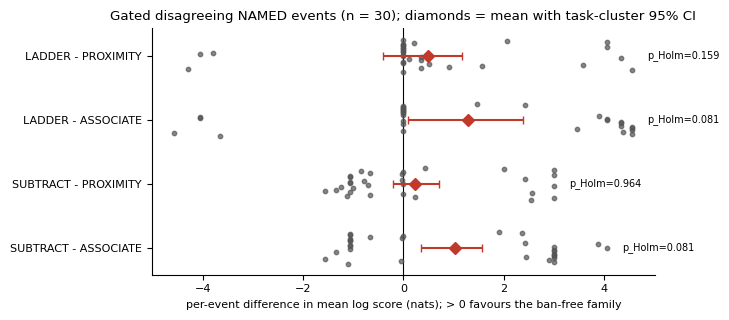

10:53:17|INFO   |figure forest_logscore_differences written


10:53:17|INFO   |[timing] analyze: 1.0s (CPU)



=== C1 NAMED (primary): 33 events, 31 gated, 30 gated disagreeing ===
advance-rule wins {'SUBTRACT': 2, 'LADDER': 7, 'ASSOCIATE': 2, 'PROXIMITY': 0}  -> advancing ['LADDER'];  unaimed share 0.067;  BRANCH: SUBTRACTION/LADDER (LADDER)


,pair,n non-zero,method,mean diff (nats),task-cluster 95% CI,p,p_Holm,Holm-significant
0,SUBTRACT-ASSOCIATE,30,asymptotic,1.021,"[0.35, 1.56]",0.0202,0.0808,False
1,SUBTRACT-PROXIMITY,28,asymptotic,0.226,"[-0.2, 0.7]",0.9636,0.9636,False
2,LADDER-ASSOCIATE,18,exact,1.290,"[0.1, 2.38]",0.0268,0.0808,False
3,LADDER-PROXIMITY,17,exact,0.496,"[-0.4, 1.16]",0.0797,0.1594,False



=== C1 UNNAMED (descriptive): 33 events, 33 gated, 32 gated disagreeing ===
advance-rule wins {'SUBTRACT': 2, 'LADDER': 7, 'ASSOCIATE': 2, 'PROXIMITY': 0}  -> advancing ['LADDER'];  unaimed share 0.031;  BRANCH: SUBTRACTION/LADDER (LADDER)


,pair,n non-zero,method,mean diff (nats),task-cluster 95% CI,p,p_Holm,Holm-significant
0,SUBTRACT-ASSOCIATE,31,asymptotic,0.926,"[0.04, 1.57]",0.0278,0.0805,False
1,SUBTRACT-PROXIMITY,29,asymptotic,0.120,"[-0.36, 0.61]",0.5665,0.5665,False
2,LADDER-ASSOCIATE,19,exact,1.417,"[0.37, 2.25]",0.0014,0.0056,True
3,LADDER-PROXIMITY,18,exact,0.612,"[0.07, 1.02]",0.0268,0.0805,False



top-1 hit rate on gated NAMED events: {'SUBTRACT': 0.363, 'LADDER': 0.774, 'ASSOCIATE': 0.452, 'PROXIMITY': 0.613}
mean log score, gated disagreeing NAMED events: {'SUBTRACT': -1.372, 'LADDER': -1.103, 'ASSOCIATE': -2.393, 'PROXIMITY': -1.599}


,sensitivity,gated disagreeing,SUBTRACT,LADDER,ASSOCIATE,PROXIMITY,advancing,branch
0,subtract_top1,30,2,7,2,0,LADDER,SUBTRACTION/LADDER (LADDER)
1,exclude_coveto_survivor,30,2,7,2,0,LADDER,SUBTRACTION/LADDER (LADDER)
2,priority_only,18,1,7,2,0,LADDER,SUBTRACTION/LADDER (LADDER)
3,token_distance_proximity,30,2,9,2,0,LADDER,SUBTRACTION/LADDER (LADDER)
4,correct_only,30,2,8,2,0,LADDER,SUBTRACTION/LADDER (LADDER)
5,exclude_subtract_undefined_or_not_surface,2,0,0,0,0,none,UNDETERMINED
6,exclude_labeller_flagged_tasks,30,2,7,2,0,LADDER,SUBTRACTION/LADDER (LADDER)


placebo rotation (NAMED): wins {'SUBTRACT': 2, 'LADDER': 9, 'ASSOCIATE': 2, 'PROXIMITY': 1} -> SUBTRACTION/LADDER (LADDER)  (skipped single-Y tasks ['T13'])
placebo label permutation (200 draws): some family advances in 100% of draws, by family {'SUBTRACT': 1.0, 'LADDER': 0.43, 'ASSOCIATE': 0.665, 'PROXIMITY': 0.465}
exploratory three-family contest (NAMED, 21 events): wins {'LADDER': 8, 'ASSOCIATE': 3, 'PROXIMITY': 0}, modal replacement = default in 77% of gated events


In [19]:
run_banner("analyze")
# method.py cmd_analyze(args) = _cpu_ram_limit(40); with Timer("analyze"): analyze(args)
# (the address-space cap is not applied in a notebook: it would cap the whole Jupyter kernel)
with Timer("analyze"):
    summary, evs = analyze(args)


def c1_overview(name: str, res: dict) -> None:
    rule = res["rule"]
    print(f"\n=== C1 {name}: {res['n_events_total']} events, {res['n_gated']} gated, "
          f"{res['n_gated_disagreeing']} gated disagreeing ===")
    print(f"advance-rule wins {rule['wins']}  -> advancing {rule['advancing'] or 'none'};  "
          f"unaimed share {res['unaimed_share']:.3f};  BRANCH: {res['branch']}")
    if res["tests"].get("run"):
        display(pd.DataFrame([{"pair": t["pair"], "n non-zero": t["n_nonzero"], "method": t["method"],
                               "mean diff (nats)": round(t["mean_diff"], 3),
                               "task-cluster 95% CI": [round(x, 2) for x in t["ci95_task_cluster"]],
                               "p": round(t["p"], 4), "p_Holm": round(t["p_holm"], 4), "Holm-significant": t["significant"]}
                              for t in res["tests"]["tests"]]))
    else:
        print("paired tests not run:", res["tests"]["reason"])


c1_overview("NAMED (primary)", summary["c1_named"])
c1_overview("UNNAMED (descriptive)", summary["c1_unnamed"])
print("\ntop-1 hit rate on gated NAMED events:", {f: (round(v, 3) if v is not None else None)
                                                 for f, v in summary["hit_rate_gated_named"].items()})
print("mean log score, gated disagreeing NAMED events:", {f: (round(v, 3) if v is not None else None)
                                                         for f, v in summary["mean_logscore_gated_disagreeing_named"].items()})
display(pd.DataFrame([{"sensitivity": k, "gated disagreeing": v["n_gated_disagreeing"], **v["wins"],
                       "advancing": "/".join(v["advancing"]) or "none", "branch": v["branch"]}
                      for k, v in summary["sensitivities"].items() if "wins" in v]))
pl = summary["placebos"]
print(f"placebo rotation (NAMED): wins {pl['rotation']['wins']} -> {pl['rotation']['branch']}  "
      f"(skipped single-Y tasks {pl['rotation']['skipped_single_event_tasks']})")
print(f"placebo label permutation ({pl['label_permutation']['n_draws']} draws): some family advances in "
      f"{pl['label_permutation']['share_any_family_advances']:.0%} of draws, by family "
      f"{pl['label_permutation']['share_by_family']}")
tf_ = summary["exploratory_not_preregistered"]["three_family_named"]
print(f"exploratory three-family contest (NAMED, {tf_['n_three_family_disagreeing']} events): wins {tf_['wins']}, "
      f"modal replacement = default in {tf_['modal_is_default_share_gated']:.0%} of gated events" if tf_["n_gated"] else
      "exploratory three-family contest: no gated events")

## 9. `audit`: independent re-derivation and placebos (`audit/rederive.py`)

The audit is a separate script that imports nothing from `analysis/` or `exposure/`. It re-implements every rule from scratch: smoothing, log scores, top-1, gate, advance rule, an exact Wilcoxon signed-rank test (dynamic programming over rank sums), Holm and the wins. It then compares every event and headline number with what `analyze` wrote, and exits non-zero on any mismatch.

It also runs three placebos that must *fail* to find an effect:
- **Sign flip:** random signs on the per-event differences. Few draws should come out Holm-significant (≈ 5%).
- **Constant forecast:** every family forecasts Uniform(S). No family should win any event.
- **Within-task rotation** of the Y-specific forecasts. Its result is reported.

Finally it re-walks the hash chain and re-hashes every committed file.

`cmd_audit` runs the script in a subprocess, unchanged except for its input. The original reads the 10,600 programs; the demo reads per-(Y, arm) counts written from the data, and the audit re-applies its own label normalisation to them. The COPY-arm copy rate is not re-derived. The number of sign-flip draws is passed on the command line.

**Note on reduced configurations.** The audit flags a p-value as a mismatch when it differs from the frozen code's p by more than 0.01, or when the two lead to different Holm decisions. The two exact tests handle ties differently: the audit enumerates tied half-ranks exactly, while scipy's exact mode assumes untied ranks. With all 33 Y the largest gap is 0.0012, and the original run reported 0 mismatches. With only a dozen Y, and therefore n ≤ 12 non-zero differences per test, the gaps can exceed 0.01 and get flagged even though every event-level number agrees.

The original pipeline stops on any flag. The notebook lists the flags and continues.

In [20]:
%%writefile demo_run/audit/rederive.py
#!/usr/bin/env python3
"""Independent re-derivation of every c1_events row and the headline numbers (plan T5 / 4.7).

Reads only data/samples.jsonl, the committed predictions/ files and commitments.log.  Imports nothing from analysis/
or exposure/: smoothing, log scores, top-1, gate, advance rule, an exact Wilcoxon signed-rank test (dynamic
programming over rank sums), Holm and the branch are re-implemented here.  Then compares against results/c1_events.jsonl
and results/c1_summary.json, and runs placebo checks that must FAIL to find an effect:
  (1) sign-flip placebo: random signs on the per-event log-score differences -> Holm-significant rarely (<= ~5%);
  (2) constant-forecast placebo: every family forecasts Uniform(S) -> no family wins any event;
  (3) within-task rotation of the Y-specific forecasts (SUBTRACT, ASSOCIATE, PROXIMITY) -> reported.
Writes results/rederive.json and exits non-zero on any mismatch.

DEMO: data/samples.jsonl is not shipped with the notebook.  The per-(Y, arm) counts (attempts, Y count, non-Y labels)
are read from data/event_stats.json, which the notebook writes from mini_demo_data.json; the COPY-arm copy rate needs
the COPY programs and is not re-derived.  argv[1] (optional) sets the number of sign-flip draws (default 200).
"""

from __future__ import annotations

import hashlib
import json
import math
import random
import sys
from collections import Counter, defaultdict
from pathlib import Path

ROOT = Path(__file__).resolve().parent.parent
TOL = 1e-9


def jl(p: Path) -> list[dict]:
    return [json.loads(x) for x in p.read_text().splitlines() if x.strip()]


def jread(p: Path):
    return json.loads(p.read_text())


# ------------------------------------------------------------------------------------------- re-implementations
def smoothed(f, surv):
    k = len(surv)
    g = {}
    if f:
        g = {a: float(b) for a, b in f.items() if (a in surv or a == "other") and b > 0}
    tot = sum(g.values())
    g = {a: b / tot for a, b in g.items()} if tot > 0 else {a: 1.0 / k for a in surv}
    p = {a: 0.98 * (0.95 * g.get(a, 0.0) + 0.05 / k) for a in surv}
    p["other"] = 0.98 * 0.95 * g.get("other", 0.0) + 0.02
    return p, g


def argmax_set(d):
    if not d:
        return []
    m = max(d.values())
    return sorted(a for a, b in d.items() if abs(b - m) < 1e-12)


def exact_wilcoxon_p(d):
    """Two-sided exact signed-rank p (zeros dropped, average ranks for ties, exact over integerised half-ranks)."""
    x = [v for v in d if v != 0]
    n = len(x)
    if n == 0:
        return 1.0
    a = sorted(range(n), key=lambda i: abs(x[i]))
    ranks = [0.0] * n
    i = 0
    while i < n:
        j = i
        while j + 1 < n and abs(x[a[j + 1]]) == abs(x[a[i]]):
            j += 1
        for k in range(i, j + 1):
            ranks[a[k]] = (i + j) / 2 + 1
        i = j + 1
    r2 = [int(round(2 * r)) for r in ranks]  # half-ranks are integers
    wplus = sum(r for r, v in zip(r2, x) if v > 0)
    tot = sum(r2)
    if n > 25:
        mu = sum(ranks) / 2
        var = sum(r * r for r in ranks) / 4
        z = (wplus / 2 - mu) / math.sqrt(var)
        return math.erfc(abs(z) / math.sqrt(2))
    counts = {0: 1}
    for r in r2:
        nxt = defaultdict(int)
        for s, c in counts.items():
            nxt[s] += c
            nxt[s + r] += c
        counts = nxt
    total = 2 ** n
    lo = sum(c for s, c in counts.items() if s <= min(wplus, tot - wplus))
    return min(1.0, 2 * lo / total)


def holm(ps):
    m = len(ps)
    order = sorted(range(m), key=lambda i: ps[i])
    out, run = [0.0] * m, 0.0
    for rank, i in enumerate(order):
        run = max(run, min(1.0, (m - rank) * ps[i]))
        out[i] = run
    return out


FAM = ["SUBTRACT", "LADDER", "ASSOCIATE", "PROXIMITY"]
PAIRS = [("SUBTRACT", "ASSOCIATE"), ("SUBTRACT", "PROXIMITY"), ("LADDER", "ASSOCIATE"), ("LADDER", "PROXIMITY")]


def score(land, surv, forecasts):
    n = sum(land.values())
    ls, t1 = {}, {}
    for f in FAM:
        p, g = smoothed(forecasts[f], surv)
        ls[f] = sum(c * math.log(p[lab]) for lab, c in land.items()) / n if n else float("nan")
        t1[f] = argmax_set(g)
    dis = len({tuple(v) for v in t1.values()}) > 1
    return ls, t1, dis


def wins_of(evs):
    w = Counter()
    for e in evs:
        for f in FAM:
            if e["ls"][f] - max(e["ls"][g] for g in FAM if g != f) >= 0.10:
                w[f] += 1
    return {f: w[f] for f in FAM}


def main() -> int:
    stats = jread(ROOT / "data" / "event_stats.json")  # DEMO: replaces samples = jl(ROOT / "data" / "samples.jsonl")
    pred = ROOT / "predictions"
    elig = jread(pred / "eligibility.json")
    asc, lad = jread(pred / "associate.json"), jread(pred / "ladder.json")
    prox, sub = jread(pred / "proximity.json"), jread(pred / "subtract_in_context.json")
    shown = [f"{e['task']}:{e['Y']}" for e in elig["eligible"]]  # DEMO: the original counts shown_programs.jsonl keys
    mine = {}
    for key in shown:
        t, y = key.split(":")
        surv = [m for m in elig["tasks"][t]["modes"] if m != y]
        fc = {"SUBTRACT": sub[key]["distribution"], "LADDER": lad[key], "ASSOCIATE": asc[key],
              "PROXIMITY": prox[key]["distribution"]}
        for arm in ("named", "unnamed"):
            st = stats.get(f"{key}:{arm}")  # DEMO: rs = rows.get((t, y, arm), []), the 50 labelled programs
            if not st:
                continue
            n_att, ny = st["n_attempts"], st["n_Y"]  # DEMO: att = labels other than 'invalid'; ny = att.count(y)
            land = Counter()
            for lab, c in st["landing"].items():  # DEMO: the audit's own normalisation, applied to the label counts
                land[lab if lab in surv else "other"] += c
            n_non = sum(land.values())
            avoid = 1 - ny / n_att if n_att else float("nan")
            ls, t1, dis = score(land, surv, fc)
            mine[(t, y, arm)] = {"avoidance": avoid, "n_nonY": n_non, "gate": (avoid >= 0.5 and n_non >= 20),
                                 "landing": dict(land), "ls": ls, "t1": t1, "dis": dis, "task": t, "Y": y, "surv": surv,
                                 "fc": fc}
    theirs = {(e["task"], e["Y"], e["event_type"].split("_")[1]): e for e in jl(ROOT / "results" / "c1_events.jsonl")}
    mism = []
    for k, m in mine.items():
        e = theirs.get(k)
        if e is None:
            mism.append(f"{k}: missing in c1_events")
            continue
        if not (abs(m["avoidance"] - e["avoidance"]) < TOL or (math.isnan(m["avoidance"]) and e["avoidance"] is None)):
            mism.append(f"{k}: avoidance {m['avoidance']} vs {e['avoidance']}")
        if m["n_nonY"] != e["n_nonY"] or m["gate"] != e["gate_pass"] or m["dis"] != e["disagreeing"]:
            mism.append(f"{k}: n_nonY/gate/disagreeing differ")
        if m["landing"] != e["landing_counts"]:
            mism.append(f"{k}: landing differs")
        for f in FAM:
            if abs(m["ls"][f] - e["logscore"][f]) > 1e-9 or m["t1"][f] != sorted(e["top1"][f]):
                mism.append(f"{k}: {f} logscore/top1 differ ({m['ls'][f]} vs {e['logscore'][f]})")
    if len(theirs) != len(mine):
        mism.append(f"event count {len(mine)} vs {len(theirs)}")
    summ = jread(ROOT / "results" / "c1_summary.json")
    head = {}
    for arm in ("named", "unnamed"):
        sel = [m for k, m in mine.items() if k[2] == arm and m["gate"] and m["dis"]]
        w = wins_of(sel)
        adv = [f for f in FAM if w[f] >= 3]
        tests = []
        if len(sel) >= 10:
            ps = [exact_wilcoxon_p([e["ls"][a] - e["ls"][b] for e in sel]) for a, b in PAIRS]
            tests = [{"pair": f"{a}-{b}", "p": p, "p_holm": q,
                      "mean_diff": sum(e["ls"][a] - e["ls"][b] for e in sel) / len(sel)}
                     for (a, b), p, q in zip(PAIRS, ps, holm(ps))]
        head[arm] = {"n_gated": sum(1 for k, m in mine.items() if k[2] == arm and m["gate"]),
                     "n_gated_disagreeing": len(sel), "wins": w, "advancing": adv, "tests": tests}
        ref = summ[f"c1_{arm}"]
        if ref["n_gated"] != head[arm]["n_gated"] or ref["n_gated_disagreeing"] != len(sel):
            mism.append(f"{arm}: gated counts differ")
        if ref["rule"]["wins"] != w or sorted(ref["rule"]["advancing"]) != sorted(adv):
            mism.append(f"{arm}: wins/advancing differ {ref['rule']['wins']} vs {w}")
        if tests and ref["tests"].get("run"):
            # This exact test enumerates the actual (tied) half-ranks; scipy's exact mode assumes untied ranks and its
            # normal approximation has its own tie correction, so p-values may differ slightly.  A mismatch is a
            # different Holm decision at 0.05 or a p gap > 0.01; every gap is reported.
            gaps = []
            for t_mine, t_ref in zip(tests, ref["tests"]["tests"]):
                gaps.append({"pair": t_mine["pair"], "p_audit": t_mine["p"], "p_frozen": t_ref["p"],
                             "p_holm_audit": t_mine["p_holm"], "p_holm_frozen": t_ref["p_holm"],
                             "method_frozen": t_ref.get("method"), "n_nonzero": t_ref.get("n_nonzero")})
                if (t_mine["p_holm"] < 0.05) != (t_ref["p_holm"] < 0.05) or abs(t_mine["p"] - t_ref["p"]) > 0.01:
                    mism.append(f"{arm} {t_mine['pair']}: p {t_mine['p']:.6g} vs {t_ref['p']:.6g} (decision or gap)")
            head[arm]["p_value_comparison"] = gaps
            head[arm]["max_abs_p_gap"] = max(abs(g["p_audit"] - g["p_frozen"]) for g in gaps)
    # exploratory three-family contest (LADDER / ASSOCIATE / PROXIMITY), recomputed independently
    fam3 = ["LADDER", "ASSOCIATE", "PROXIMITY"]
    ref3 = summ.get("exploratory_not_preregistered", {}).get("three_family_named")
    g3 = [m for k, m in mine.items() if k[2] == "named" and m["gate"]]
    s3 = [m for m in g3 if len({tuple(m["t1"][f]) for f in fam3}) > 1]
    w3 = Counter()
    for e in s3:
        for f in fam3:
            if e["ls"][f] - max(e["ls"][g] for g in fam3 if g != f) >= 0.10:
                w3[f] += 1

    def hit_of(m, f):
        mod = argmax_set(m["landing"])
        return len(set(mod) & set(m["t1"][f])) / (len(mod) * len(m["t1"][f])) if mod and m["t1"][f] else 0.0

    hit3 = {f: (sum(hit_of(m, f) for m in g3) / len(g3)) if g3 else None for f in fam3}
    head["three_family_named"] = {"n_events": len(s3), "wins": {f: w3[f] for f in fam3}, "hit_rate_gated": hit3}
    if ref3 is not None:
        if ref3["n_three_family_disagreeing"] != len(s3) or ref3["wins"] != {f: w3[f] for f in fam3}:
            mism.append(f"three-family wins differ {ref3['wins']} vs {dict(w3)}")
        for f in fam3:
            if ref3["hit_rate_gated"][f] is not None and abs(ref3["hit_rate_gated"][f] - hit3[f]) > 1e-9:
                mism.append(f"three-family hit rate {f} differs")
    # copy rates and NAMED avoidance (headline descriptive numbers)
    # DEMO: the copy rate needs the COPY-arm programs and is not re-derived here
    nav = [m["avoidance"] for k, m in mine.items() if k[2] == "named" and not math.isnan(m["avoidance"])]
    head["named_avoidance_mean"] = sum(nav) / len(nav) if nav else None
    # snap-back to the default: mean share of attempts equal to the context-free default, per arm
    dshare = {}
    for arm in ("named", "unnamed"):  # DEMO: the COPY arm needs its programs
        vals = []
        for key in shown:
            t, y = key.split(":")
            st = stats.get(f"{key}:{arm}")
            if st and st["n_attempts"]:
                vals.append(st["landing"].get(elig["tasks"][t]["default"], 0) / st["n_attempts"])
        dshare[arm] = sum(vals) / len(vals) if vals else None
    head["default_share_mean_by_arm"] = dshare
    gn = [m for k, m in mine.items() if k[2] == "named" and m["gate"]]
    head["named_gated_modal_is_default"] = [sum(1 for m in gn if elig["tasks"][m["task"]]["default"] in argmax_set(m["landing"])),
                                            len(gn)]
    # ------------------------------------------------------------------------------------------- placebos
    rng = random.Random(11)
    sel = [m for k, m in mine.items() if k[2] == "named" and m["gate"] and m["dis"]]
    flips_sig = 0
    n_draws = int(sys.argv[1]) if len(sys.argv) > 1 else 200  # DEMO: settable from the notebook (original: 200)
    if len(sel) >= 10:
        for _ in range(n_draws):
            ps = []
            for a, b in PAIRS:
                d = [(e["ls"][a] - e["ls"][b]) * rng.choice((-1, 1)) for e in sel]
                ps.append(exact_wilcoxon_p(d))
            flips_sig += any(q < 0.05 for q in holm(ps))
    const = []
    for m in mine.values():
        if m["gate"]:
            ls, _, _ = score(Counter(m["landing"]), m["surv"], {f: None for f in FAM})
            const.append({"ls": ls})
    rot_events = []
    by_task = defaultdict(list)
    for k, m in mine.items():
        if k[2] == "named":
            by_task[k[0]].append(m)
    for t, ms in by_task.items():
        if len(ms) < 2:
            continue
        for i, m in enumerate(ms):
            fc2 = dict(m["fc"])
            for f in ("SUBTRACT", "ASSOCIATE", "PROXIMITY"):
                fc2[f] = ms[(i + 1) % len(ms)]["fc"][f]
            ls, t1, dis = score(Counter(m["landing"]), m["surv"], fc2)
            if m["gate"] and dis:
                rot_events.append({"ls": ls})
    placebo = {"sign_flip": {"n_events": len(sel), "n_draws": n_draws if len(sel) >= 10 else 0,
                             "share_any_holm_significant": (flips_sig / n_draws) if len(sel) >= 10 else None},
               "constant_uniform_forecasts": {"n_gated_events": len(const), "wins": wins_of(const)},
               "rotation_Y_specific": {"n_gated_disagreeing": len(rot_events), "wins": wins_of(rot_events),
                                       "advancing": [f for f, v in wins_of(rot_events).items() if v >= 3]}}
    const_ok = all(v == 0 for v in placebo["constant_uniform_forecasts"]["wins"].values())
    flip_ok = placebo["sign_flip"]["share_any_holm_significant"] is None or placebo["sign_flip"]["share_any_holm_significant"] <= 0.10
    # ------------------------------------------------------------------------------------- chain + timing
    lines = (ROOT / "commitments.log").read_text().splitlines()
    prev, chain_ok = "0" * 64, True
    for ln in lines:
        rec = json.loads(ln)
        chain_ok &= rec["prev_line_sha256"] == prev
        prev = hashlib.sha256(ln.encode()).hexdigest()
    files_ok = True
    for ln in lines:
        rec = json.loads(ln)
        if rec["kind"].startswith(("COMMIT1:", "COMMIT2:")) and rec.get("file"):
            p = ROOT / rec["file"]
            files_ok &= p.exists() and hashlib.sha256(p.read_bytes()).hexdigest() == rec["sha256"]
    out = {"n_events_rederived": len(mine), "mismatches": mism, "n_mismatches": len(mism), "headline": head,
           "placebo": placebo, "placebo_constant_forecast_no_wins": const_ok, "placebo_sign_flip_level_ok": flip_ok,
           "chain_verifies": chain_ok, "committed_files_unchanged": files_ok}
    (ROOT / "results" / "rederive.json").write_text(json.dumps(out, indent=1))
    print(json.dumps({k: v for k, v in out.items() if k != "headline"}, indent=1)[:4000])
    print("HEADLINE", json.dumps(head)[:3000])
    return 0 if (not mism and chain_ok and files_ok and const_ok) else 1


if __name__ == "__main__":
    sys.exit(main())

Writing demo_run/audit/rederive.py


In [21]:
def cmd_audit(args) -> None:
    # _cpu_ram_limit(40)  (not applied in a notebook)
    with Timer("audit"):
        r = subprocess.run([sys.executable, "audit/rederive.py", str(N_SIGNFLIP_DRAWS)], cwd=ROOT, capture_output=True,
                           text=True)  # DEMO: the number of sign-flip draws is passed as argv[1]
        (LOGS / "audit.out").write_text(r.stdout + r.stderr)
        logger.info(r.stdout[-3000:])
        if r.returncode != 0:
            # original: raise RuntimeError(f"audit failed: {r.stderr[-1500:]}")
            # DEMO: reported instead of raised, so that a reduced configuration still runs to the end (see the note above)
            logger.warning(f"audit exit code {r.returncode} (the flagged mismatches are listed below); stderr: "
                           f"{r.stderr[-1500:]!r}")
        # fold the audit record into method_out.json (metadata), as the plan's 4.7 asks
        mo_path, red = ROOT / "method_out.json", read_json(RESULTS / "rederive.json")
        if mo_path.exists():
            mo = read_json(mo_path)
            md = mo["metadata"]
            md["audit_rederive"] = {k: red[k] for k in ("n_events_rederived", "n_mismatches", "headline", "placebo",
                                                        "chain_verifies", "committed_files_unchanged")}
            md["gpu_hours_note"] = (f"summary.gpu_hours ({md['summary']['gpu_hours']:.3f}) counts the completed stage-1 and "
                                    f"stage-2 runs; the aborted first stage-1 attempt (stop-token bug, about "
                                    f"{ABORTED_STAGE1_MIN} min) brings the total to about 1.0 GPU-hour on one NVIDIA L4")
            md["gpu_hours_including_aborted_attempt"] = round(md["summary"]["gpu_hours"] + ABORTED_STAGE1_MIN / 60, 3)
            md["exploratory_note"] = ("summary.exploratory_not_preregistered (three-family LADDER/ASSOCIATE/PROXIMITY "
                                      "contest) was added after the commits and is not part of the frozen C1 analysis")
            mo_path.write_text(json.dumps(mo))
            logger.info("audit record merged into method_out.json metadata")


# DEMO: the per-(Y, arm) counts the audit re-derives its events from (the original audit reads data/samples.jsonl)
write_json(DATA / "event_stats.json", {f"{r['task']}:{r['Y']}:{r['arm']}": {
    "n_attempts": r["n_attempts"], "n_Y": r["n_attempts"] - r["n_nonY"], "landing": r["landing_counts"]} for r in event_rows})
run_banner("audit")
cmd_audit(args)
red = read_json(RESULTS / "rederive.json")
print(f"audit: {red['n_events_rederived']} events re-derived, {red['n_mismatches']} mismatches; chain verifies "
      f"{red['chain_verifies']}; committed files unchanged {red['committed_files_unchanged']}")
print(f"  flagged mismatches: {red['mismatches'] or 'none'}")
print(f"  sign-flip placebo: {red['placebo']['sign_flip']}")
print(f"  constant-forecast placebo: {red['placebo']['constant_uniform_forecasts']}  (no wins: "
      f"{red['placebo_constant_forecast_no_wins']})")
print(f"  rotation of the Y-specific forecasts: {red['placebo']['rotation_Y_specific']}")
for arm in ("named", "unnamed"):
    for gp in red["headline"][arm].get("p_value_comparison", []):
        print(f"  {arm:8s} {gp['pair']:<20} p audit {gp['p_audit']:.4f} vs frozen {gp['p_frozen']:.4f} "
              f"({gp['method_frozen']}); p_Holm {gp['p_holm_audit']:.4f} vs {gp['p_holm_frozen']:.4f}")

10:53:17|INFO   |=== method.py audit (cpus=2) ===


10:53:17|INFO   |"named": {"n_gated": 31, "n_gated_disagreeing": 30, "wins": {"SUBTRACT": 2, "LADDER": 7, "ASSOCIATE": 2, "PROXIMITY": 0}, "advancing": ["LADDER"], "tests": [{"pair": "SUBTRACT-ASSOCIATE", "p": 0.020203251026672902, "p_holm": 0.08081300410669161, "mean_diff": 1.0205870718097996}, {"pair": "SUBTRACT-PROXIMITY", "p": 0.9636487141044751, "p_holm": 0.9636487141044751, "mean_diff": 0.22625259645513485}, {"pair": "LADDER-ASSOCIATE", "p": 0.02561187744140625, "p_holm": 0.08081300410669161, "mean_diff": 1.2902032816707767}, {"pair": "LADDER-PROXIMITY", "p": 0.079498291015625, "p_holm": 0.15899658203125, "mean_diff": 0.4958688063161118}], "p_value_comparison": [{"pair": "SUBTRACT-ASSOCIATE", "p_audit": 0.020203251026672902, "p_frozen": 0.02020325102667289, "p_holm_audit": 0.08081300410669161, "p_holm_frozen": 0.08081300410669157, "method_frozen": "asymptotic", "n_nonzero": 30}, {"pair": "SUBTRACT-PROXIMITY", "p_audit": 0.9636487141044751, "p_frozen": 0.9636487141044751, "p_holm_

10:53:17|INFO   |[timing] audit: 0.3s (CPU)


audit: 66 events re-derived, 0 mismatches; chain verifies True; committed files unchanged True
  flagged mismatches: none
  sign-flip placebo: {'n_events': 30, 'n_draws': 200, 'share_any_holm_significant': 0.055}
  constant-forecast placebo: {'n_gated_events': 64, 'wins': {'SUBTRACT': 0, 'LADDER': 0, 'ASSOCIATE': 0, 'PROXIMITY': 0}}  (no wins: True)
  rotation of the Y-specific forecasts: {'n_gated_disagreeing': 29, 'wins': {'SUBTRACT': 2, 'LADDER': 9, 'ASSOCIATE': 2, 'PROXIMITY': 1}, 'advancing': ['LADDER']}
  named    SUBTRACT-ASSOCIATE   p audit 0.0202 vs frozen 0.0202 (asymptotic); p_Holm 0.0808 vs 0.0808
  named    SUBTRACT-PROXIMITY   p audit 0.9636 vs frozen 0.9636 (asymptotic); p_Holm 0.9636 vs 0.9636
  named    LADDER-ASSOCIATE     p audit 0.0256 vs frozen 0.0268 (exact); p_Holm 0.0808 vs 0.0808
  named    LADDER-PROXIMITY     p audit 0.0795 vs frozen 0.0797 (exact); p_Holm 0.1590 vs 0.1594
  unnamed  SUBTRACT-ASSOCIATE   p audit 0.0278 vs frozen 0.0278 (asymptotic); p_Holm 0.

## 10. Results: recomputed vs published

The first table sets every event-level number recomputed above beside the value published by the original full run (`results/c1_summary.json`, `results/rederive.json`). With the original configuration (all 33 Y, 10,000 bootstrap resamples, 200 placebo draws), the frozen code reproduces them exactly. With a reduced configuration the counts cover fewer Y, and the bootstrap CIs and placebo shares are noisier.

The second table quotes the numbers that need the 10,600 individual programs: copy rates, snap-back to the default by arm, NAMED-vs-UNNAMED agreement, C1-exposure and compute. They are context only, not recomputed here.

In [22]:
REF = data["metadata"]["reference_results"]


def wins_str(w: dict) -> str:
    return " / ".join(str(w[f]) for f in c1.FAMILIES)  # SUBTRACT / LADDER / ASSOCIATE / PROXIMITY


def fmt(x, nd: int = 3) -> str:
    if x is None:
        return "-"
    return f"{x:.{nd}f}" if isinstance(x, float) else str(x)


cmp_rows = []


def add(quantity: str, demo, orig) -> None:
    cmp_rows.append({"quantity": quantity, "this notebook": demo, "original run": orig, "same": demo == orig})


for arm in ("named", "unnamed"):
    mine, ref = summary[f"c1_{arm}"], REF[f"c1_{arm}"]
    A = arm.upper()
    add(f"{A}: events / gated / gated disagreeing",
        f"{mine['n_events_total']} / {mine['n_gated']} / {mine['n_gated_disagreeing']}",
        f"{ref['n_events_total']} / {ref['n_gated']} / {ref['n_gated_disagreeing']}")
    add(f"{A}: advance-rule wins S / L / A / P", wins_str(mine["rule"]["wins"]), wins_str(ref["wins"]))
    add(f"{A}: frozen branch", mine["branch"], ref["branch"])
    mt = {t["pair"]: t for t in mine["tests"]["tests"]} if mine["tests"].get("run") else {}
    for t in ref["tests"]:
        m = mt.get(t["pair"])
        add(f"{A}: {t['pair']} mean diff, p, p_Holm",
            f"{m['mean_diff']:+.3f}, {m['p']:.4f}, {m['p_holm']:.4f}" if m else "not run (< 10 events)",
            f"{t['mean_diff']:+.3f}, {t['p']:.4f}, {t['p_holm']:.4f}")
        add(f"{A}: {t['pair']} task-cluster 95% CI",
            f"[{m['ci95_task_cluster'][0]:+.2f}, {m['ci95_task_cluster'][1]:+.2f}]" if m else "not run (< 10 events)",
            f"[{t['ci95_task_cluster'][0]:+.2f}, {t['ci95_task_cluster'][1]:+.2f}]")
add("NAMED: top-1 hit rate S / L / A / P (gated events)",
    " / ".join(fmt(summary["hit_rate_gated_named"][f], 2) for f in c1.FAMILIES),
    " / ".join(fmt(REF["hit_rate_gated_named"][f], 2) for f in c1.FAMILIES))
for k, v in REF["sensitivities"].items():
    m = summary["sensitivities"].get(k)
    add(f"sensitivity '{k}': wins, branch", f"{wins_str(m['wins'])}, {m['branch']}" if m else "-",
        f"{wins_str(v['wins'])}, {v['branch']}")
pr, pm = REF["placebos"], summary["placebos"]
add("placebo rotation (NAMED): wins", wins_str(pm["rotation"]["wins"]), wins_str(pr["rotation"]["wins"]))
add("placebo label permutation: share of draws in which some family advances",
    fmt(pm["label_permutation"]["share_any_family_advances"]), fmt(pr["label_permutation"]["share_any_family_advances"]))
t3, r3 = summary["exploratory_not_preregistered"]["three_family_named"], REF["three_family_named"]
add("exploratory three-family (NAMED): events; wins L / A / P",
    f"{t3['n_three_family_disagreeing']}; {t3['wins']['LADDER']} / {t3['wins']['ASSOCIATE']} / {t3['wins']['PROXIMITY']}",
    f"{r3['n_three_family_disagreeing']}; {r3['wins']['LADDER']} / {r3['wins']['ASSOCIATE']} / {r3['wins']['PROXIMITY']}")
add("audit: mismatches", red["n_mismatches"], REF["audit_n_mismatches"])
add("audit sign-flip placebo: share of draws Holm-significant",
    fmt(red["placebo"]["sign_flip"]["share_any_holm_significant"]),
    fmt(REF["audit_placebo"]["sign_flip"]["share_any_holm_significant"]))
add("audit constant-forecast placebo: wins S / L / A / P",
    wins_str(red["placebo"]["constant_uniform_forecasts"]["wins"]),
    wins_str(REF["audit_placebo"]["constant_uniform_forecasts"]["wins"]))
cmp_table = pd.DataFrame(cmp_rows)
display(cmp_table)
print(f"{int(cmp_table['same'].sum())}/{len(cmp_table)} rows identical to the original run (N_Y={N_Y}, N_BOOT={N_BOOT}, "
      f"N_BOOT_SECONDARY={N_BOOT_SECONDARY}, N_PERM_DRAWS={N_PERM_DRAWS}, N_SIGNFLIP_DRAWS={N_SIGNFLIP_DRAWS})")

ctx = REF["sample_level_context"]
dsh = ctx["default_share_mean_by_arm"]
H = "original run (not recomputed here)"
display(pd.DataFrame([
    {H: "programs generated and labelled", "value": f"{ctx['n_samples']}  {ctx['n_by_arm']}"},
    {H: "labeller source", "value": str(ctx["labeller_sources"])},
    {H: "copy rate (share of COPY attempts labelled Y), mean / median over Y",
     "value": f"{ctx['copy_rate_summary']['mean']:.2f} / {ctx['copy_rate_summary']['median']:.2f}"},
    {H: "snap-back: default share COPY / final veto / NAMED / UNNAMED",
     "value": f"{dsh['copy']:.2f} / {dsh['veto_final']:.2f} / {dsh['named']:.2f} / {dsh['unnamed']:.2f}  (NAMED / UNNAMED "
              f"recomputed here by the audit: {fmt(red['headline']['default_share_mean_by_arm']['named'], 2)} / "
              f"{fmt(red['headline']['default_share_mean_by_arm']['unnamed'], 2)})"},
    {H: "NAMED vs UNNAMED: same modal replacement / JS-consistent landings",
     "value": f"{ctx['named_vs_unnamed_summary']['modal_equal_share']:.2f} / {ctx['named_vs_unnamed_summary']['js_consistent_share']:.2f}"},
    {H: "C1-exposure (ban's modal survivor vs the veto's)",
     "value": f"{ctx['c1_exposure']['n_events']} events -> {ctx['c1_exposure']['verdict']}"},
    {H: "advance rule under a no-information null (unit test T1(f), simulated)",
     "value": f"some family advances in {REF['advance_rule_null_calibration']['null_any_family_advances_rate']:.0%} of "
              f"draws; Holm-Wilcoxon errs in {REF['advance_rule_null_calibration']['null_holm_any_significant_rate']:.0%}"},
    {H: "compute", "value": f"{ctx['gpu_hours_completed_runs']:.2f} GPU-hours (completed runs, one NVIDIA L4); judge "
                            f"spend USD {ctx['openrouter_spend_usd']:.3f}"},
]))

,quantity,this notebook,original run,same
0,NAMED: events / gated / gated disagreeing,33 / 31 / 30,33 / 31 / 30,True
1,NAMED: advance-rule wins S / L / A / P,2 / 7 / 2 / 0,2 / 7 / 2 / 0,True
2,NAMED: frozen branch,SUBTRACTION/LADDER (LADDER),SUBTRACTION/LADDER (LADDER),True
3,"NAMED: SUBTRACT-ASSOCIATE mean diff, p, p_Holm","+1.021, 0.0202, 0.0808","+1.021, 0.0202, 0.0808",True
4,NAMED: SUBTRACT-ASSOCIATE task-cluster 95% CI,"[+0.35, +1.56]","[+0.35, +1.56]",True
5,"NAMED: SUBTRACT-PROXIMITY mean diff, p, p_Holm","+0.226, 0.9636, 0.9636","+0.226, 0.9636, 0.9636",True
6,NAMED: SUBTRACT-PROXIMITY task-cluster 95% CI,"[-0.20, +0.70]","[-0.20, +0.70]",True
7,"NAMED: LADDER-ASSOCIATE mean diff, p, p_Holm","+1.290, 0.0268, 0.0808","+1.290, 0.0268, 0.0808",True
8,NAMED: LADDER-ASSOCIATE task-cluster 95% CI,"[+0.10, +2.38]","[+0.10, +2.38]",True
9,"NAMED: LADDER-PROXIMITY mean diff, p, p_Holm","+0.496, 0.0797, 0.1594","+0.496, 0.0797, 0.1594",True


36/36 rows identical to the original run (N_Y=33, N_BOOT=10000, N_BOOT_SECONDARY=2000, N_PERM_DRAWS=200, N_SIGNFLIP_DRAWS=200)


,original run (not recomputed here),value
0,programs generated and labelled,"10600 {'copy': 1650, 'veto': 4650, 'baseline': 240, 'na..."
1,labeller source,"{'runtime+ast': 7478, 'judge': 1398, 'extraction': 1577,..."
2,"copy rate (share of COPY attempts labelled Y), mean / me...",0.93 / 1.00
3,snap-back: default share COPY / final veto / NAMED / UNN...,0.05 / 0.10 / 0.72 / 0.82 (NAMED / UNNAMED recomputed h...
4,NAMED vs UNNAMED: same modal replacement / JS-consistent...,0.88 / 0.79
5,C1-exposure (ban's modal survivor vs the veto's),2 events -> CONFIRM
6,advance rule under a no-information null (unit test T1(f...,some family advances in 85% of draws; Holm-Wilcoxon errs...
7,compute,"0.57 GPU-hours (completed runs, one NVIDIA L4); judge sp..."


### Where does the replacement land?

**Top panel.** For every NAMED event, it splits the non-Y attempts by what they landed on:
- the context-free default (the LADDER forecast);
- the model's own associate (ASSOCIATE top-1, when it differs from the default);
- the survivor nearest the shown program (PROXIMITY top-1, when it differs from both);
- any other survivor;
- `other`, an algorithm outside the task's catalogue.

Events marked × fail the gate (avoidance < 0.5 or < 20 non-Y attempts), and \* marks priority Y.

**Bottom row:**
- the top-1 hit rate of each family on gated NAMED events, with the published values as black diamonds;
- each family's log score on every gated disagreeing NAMED event, with the mean as a bar;
- how often Y re-emerges across the three veto rounds. Coloured lines are the Y for which SUBTRACT-IN-CONTEXT is defined.

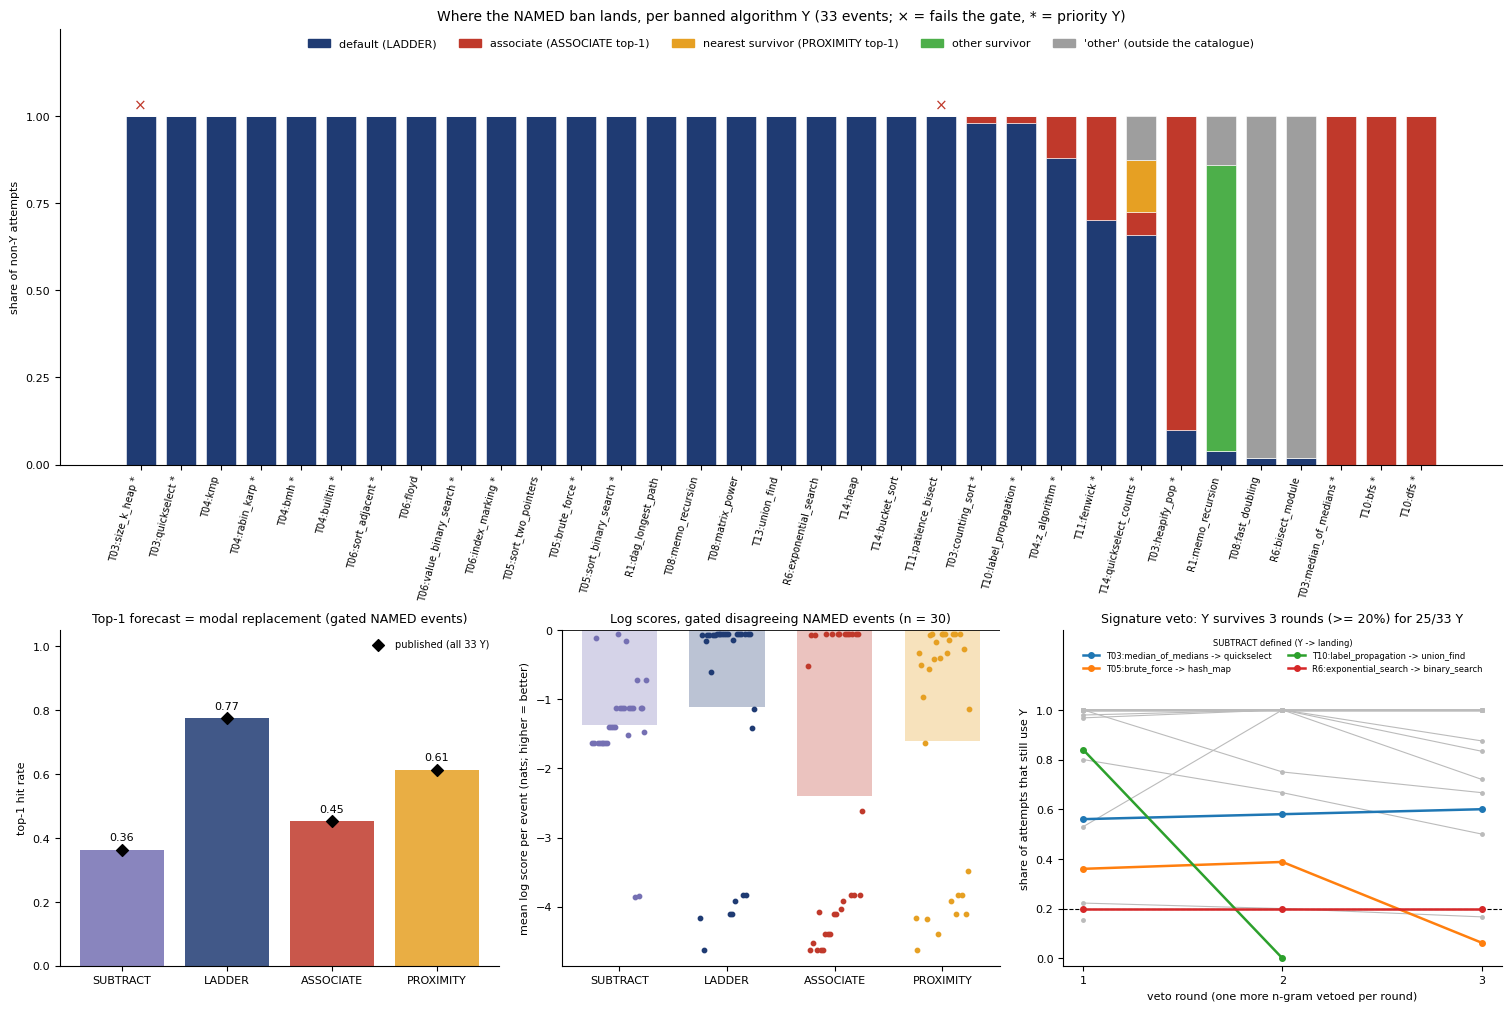

NAMED ban: the modal replacement is the context-free default in 24/31 gated events (14/18 for priority Y, whose own 'standard alternative' differs from the default)
frozen C1 branch (NAMED): SUBTRACTION/LADDER (LADDER); advance-rule wins S / L / A / P = 2 / 7 / 2 / 0


In [23]:
named_evs = [e for e in evs if e["arm"] == "named"]
FAM_COLORS = {"SUBTRACT": "#7570b3", "LADDER": "#1f3b73", "ASSOCIATE": "#c0392b", "PROXIMITY": "#e6a023"}
CAT_COLORS = {"default (LADDER)": "#1f3b73", "associate (ASSOCIATE top-1)": "#c0392b",
              "nearest survivor (PROXIMITY top-1)": "#e6a023", "other survivor": "#4daf4a",
              "'other' (outside the catalogue)": "#9e9e9e"}


def landing_parts(e: dict) -> dict:
    """Share of an event's non-Y attempts landing on the default, the associate, the nearest survivor, ..."""
    land, n = e["landing_counts"], max(e["n_nonY"], 1)
    dflt = {e["default"]}
    assoc_t1 = set(e["top1"]["ASSOCIATE"]) - dflt
    prox_t1 = set(e["top1"]["PROXIMITY"]) - dflt - assoc_t1
    parts = {"default (LADDER)": land.get(e["default"], 0),
             "associate (ASSOCIATE top-1)": sum(land.get(x, 0) for x in assoc_t1),
             "nearest survivor (PROXIMITY top-1)": sum(land.get(x, 0) for x in prox_t1),
             "'other' (outside the catalogue)": land.get(c1.OTHER, 0)}
    parts["other survivor"] = sum(land.values()) - sum(parts.values())
    return {c: parts[c] / n for c in CAT_COLORS}


fig = plt.figure(figsize=(15, 10), constrained_layout=True)
gs = fig.add_gridspec(2, 3, height_ratios=[1.3, 1])
ax = fig.add_subplot(gs[0, :])
order = sorted(range(len(named_evs)), key=lambda i: -landing_parts(named_evs[i])["default (LADDER)"])
for xi, i in enumerate(order):
    e = named_evs[i]
    bottom = 0.0
    for c, v in landing_parts(e).items():
        ax.bar(xi, v, bottom=bottom, color=CAT_COLORS[c], width=0.75, edgecolor="white", linewidth=0.4)
        bottom += v
    if not e["gate_pass"]:
        ax.text(xi, 1.01, "×", ha="center", va="bottom", fontsize=11, color="#c0392b")
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{named_evs[i]['task']}:{named_evs[i]['Y']}{' *' if named_evs[i]['priority'] else ''}"
                    for i in order], rotation=75, ha="right", fontsize=7)
ax.set_ylim(0, 1.25)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_ylabel("share of non-Y attempts")
ax.set_title(f"Where the NAMED ban lands, per banned algorithm Y ({len(named_evs)} events; × = fails the gate, "
             f"* = priority Y)", fontsize=10)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in CAT_COLORS.values()], list(CAT_COLORS), ncol=5,
          loc="upper center", frameon=False, fontsize=8)

ax1 = fig.add_subplot(gs[1, 0])
hv = [summary["hit_rate_gated_named"][f] or 0.0 for f in c1.FAMILIES]
ax1.bar(range(4), hv, color=[FAM_COLORS[f] for f in c1.FAMILIES], alpha=0.85)
ax1.scatter(range(4), [REF["hit_rate_gated_named"][f] for f in c1.FAMILIES], marker="D", color="black", zorder=3,
            label="published (all 33 Y)")
for i, v in enumerate(hv):
    ax1.text(i, v + 0.03, f"{v:.2f}", ha="center", fontsize=8)
ax1.set_xticks(range(4))
ax1.set_xticklabels(c1.FAMILIES, fontsize=8)
ax1.set_ylim(0, 1.05)
ax1.set_ylabel("top-1 hit rate")
ax1.set_title("Top-1 forecast = modal replacement (gated NAMED events)", fontsize=9)
ax1.legend(frameon=False, fontsize=7, loc="upper right")

ax2 = fig.add_subplot(gs[1, 1])
sel_gd = [e for e in named_evs if e["gate_pass"] and e["disagreeing"]]
for i, f in enumerate(c1.FAMILIES):
    vals = [e["logscore"][f] for e in sel_gd]
    if vals:
        ax2.bar(i, np.mean(vals), color=FAM_COLORS[f], alpha=0.3, width=0.7)
        ax2.scatter(np.full(len(vals), i) + np.linspace(-0.25, 0.25, len(vals)), vals, s=10, color=FAM_COLORS[f], zorder=3)
ax2.axhline(0, color="black", lw=0.6)
ax2.set_xticks(range(4))
ax2.set_xticklabels(c1.FAMILIES, fontsize=8)
ax2.set_ylabel("mean log score per event (nats; higher = better)")
ax2.set_title(f"Log scores, gated disagreeing NAMED events (n = {len(sel_gd)})", fontsize=9)

ax3 = fig.add_subplot(gs[1, 2])
for k in KEYS:
    xs = sorted(rounds[k])
    ys = [rounds[k][r]["reemerge"] for r in xs]
    if sub[k]["undefined"]:
        ax3.plot(xs, ys, marker="o", ms=2.5, lw=0.8, color="#bbbbbb", zorder=2)
    else:
        ax3.plot(xs, ys, marker="o", ms=4, lw=1.8, zorder=3, label=f"{k} -> {max(sub[k]['distribution'], key=sub[k]['distribution'].get)}")
ax3.axhline(REEMERGE_MIN, color="black", ls="--", lw=0.8)
ax3.set_xticks([1, 2, 3])
ax3.set_xlabel("veto round (one more n-gram vetoed per round)")
ax3.set_ylabel("share of attempts that still use Y")
ax3.set_ylim(-0.03, 1.32)
ax3.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax3.set_title(f"Signature veto: Y survives {MAX_ROUNDS} rounds (>= {REEMERGE_MIN:.0%}) for "
              f"{sum(v['not_carried_by_surface_tokens'] for v in sub.values())}/{len(KEYS)} Y", fontsize=9)
if any(not v["undefined"] for v in sub.values()):
    ax3.legend(frameon=False, fontsize=6, title="SUBTRACT defined (Y -> landing)", title_fontsize=6, loc="upper center",
               ncol=2)
fig.savefig(FIGS / "demo_results_overview.png", dpi=150, bbox_inches="tight")
plt.show()

gated_n = [e for e in named_evs if e["gate_pass"]]
prio_n = [e for e in gated_n if e["priority"]]
print(f"NAMED ban: the modal replacement is the context-free default in {sum(e['default'] in e['modal'] for e in gated_n)}"
      f"/{len(gated_n)} gated events ({sum(e['default'] in e['modal'] for e in prio_n)}/{len(prio_n)} for priority Y, "
      f"whose own 'standard alternative' differs from the default)")
print(f"frozen C1 branch (NAMED): {summary['c1_named']['branch']}; advance-rule wins S / L / A / P = "
      f"{wins_str(summary['c1_named']['rule']['wins'])}")